## Part A – executed on Google Colab (Tesla T4)
### A0. Hardware check (R1-2)

In [1]:
import torch

print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA: True
GPU: Tesla T4


In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


### A1. Case-level pre-processing: case split before slicing, mask used only for labels, T2w only, 8-bit PNG (R1-1, R2-2, R2-4 to R2-7, R2-28)
This cell is the pre-processing script executed on the full BraTS 2023 training set.

In [ ]:

"""
Patient-level preprocessing for the Brain MRI Classification study.

Purpose
-------
Fix the data-leakage problem in the previous slice-level split.

"""

import os
import random
from pathlib import Path

import cv2
import nibabel as nib
import numpy as np
import pandas as pd


# ============================================================
# CONFIGURATION
# ============================================================

RAW_DATA_PATH = Path(
    r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\raw"
    r"\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData"
)

OUTPUT_ROOT = Path(
    r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\raw"
    r"patient_level_processed"
)

IMAGE_DIR = OUTPUT_ROOT / "images"
METADATA_CSV = OUTPUT_ROOT / "metadata.csv"
PATIENT_SPLIT_CSV = OUTPUT_ROOT / "patient_split.csv"

IMG_SIZE = 224
SEED = 42

# Patient-level split. Change only if the manuscript specifies another
# protocol and then document the exact final values.
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

MODALITY_TOKEN = "t2w"
SEG_TOKEN = "seg"


# ============================================================
# REPRODUCIBILITY
# ============================================================

random.seed(SEED)
np.random.seed(SEED)

if abs((TRAIN_RATIO + VAL_RATIO + TEST_RATIO) - 1.0) > 1e-9:
    raise ValueError("TRAIN_RATIO + VAL_RATIO + TEST_RATIO must equal 1.0")

if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset path not found: {RAW_DATA_PATH}")

IMAGE_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# NORMALIZATION
# ============================================================

def normalize_current_pipeline(img: np.ndarray) -> np.ndarray:
    """
    Reproduces the normalization used in the previous notebook:
        max_val = max(img)
        if max_val == 0: return img
        img = img - min(img)
        img = img / max_val

    """
    max_val = float(np.max(img))
    if max_val == 0:
        return img.astype(np.float32)

    img = img.astype(np.float32)
    img = img - float(np.min(img))
    img = img / max_val
    return img


# ============================================================
# FILE DISCOVERY
# ============================================================

def find_first_file(patient_path: Path, token: str):
    matches = sorted(
        p for p in patient_path.iterdir()
        if p.is_file() and token.lower() in p.name.lower()
        and p.name.lower().endswith((".nii", ".nii.gz"))
    )
    return matches[0] if matches else None


patient_folders = sorted(
    p for p in RAW_DATA_PATH.iterdir()
    if p.is_dir()
)

if not patient_folders:
    raise RuntimeError("No patient folders were found.")

print(f"Patients discovered: {len(patient_folders)}")


# ============================================================
# PATIENT-LEVEL SPLIT
# ============================================================

patient_ids = [p.name for p in patient_folders]

rng = random.Random(SEED)
rng.shuffle(patient_ids)

n = len(patient_ids)
n_train = int(n * TRAIN_RATIO)
n_val = int(n * VAL_RATIO)

# Ensure every patient belongs to exactly one partition.
train_ids = patient_ids[:n_train]
val_ids = patient_ids[n_train:n_train + n_val]
test_ids = patient_ids[n_train + n_val:]

patient_split = {
    pid: "train" for pid in train_ids
}
patient_split.update({
    pid: "val" for pid in val_ids
})
patient_split.update({
    pid: "test" for pid in test_ids
})

split_df = pd.DataFrame(
    [{"patient_id": pid, "split": patient_split[pid]} for pid in sorted(patient_split)]
)

split_df.to_csv(PATIENT_SPLIT_CSV, index=False)

# Hard leakage check.
train_set = set(train_ids)
val_set = set(val_ids)
test_set = set(test_ids)

assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

print("\nPATIENT-LEVEL SPLIT")
print(f"Train patients: {len(train_set)}")
print(f"Validation patients: {len(val_set)}")
print(f"Test patients: {len(test_set)}")
print("Patient overlap check: PASSED")


# ============================================================
# SLICE EXTRACTION
# ============================================================

rows = []
slice_counter = {"train": 0, "val": 0, "test": 0}
skipped = []

for patient_path in patient_folders:
    patient_id = patient_path.name
    split = patient_split[patient_id]

    image_path = find_first_file(patient_path, MODALITY_TOKEN)
    seg_path = find_first_file(patient_path, SEG_TOKEN)

    if image_path is None or seg_path is None:
        skipped.append({
            "patient_id": patient_id,
            "reason": "missing T2w or segmentation file",
        })
        continue

    try:
        volume = nib.load(str(image_path)).get_fdata()
        seg = nib.load(str(seg_path)).get_fdata()
    except Exception as exc:
        skipped.append({
            "patient_id": patient_id,
            "reason": f"load error: {exc}",
        })
        continue

    if volume.shape != seg.shape:
        skipped.append({
            "patient_id": patient_id,
            "reason": f"shape mismatch: MRI={volume.shape}, SEG={seg.shape}",
        })
        continue

    for slice_id in range(volume.shape[2]):
        image_slice = volume[:, :, slice_id]
        seg_slice = seg[:, :, slice_id]

        # EXACT retention rule from the previous notebook:
        # remove only MRI slices whose maximum intensity is zero.
        # The segmentation mask is NOT used for slice selection.
        if np.max(image_slice) == 0:
            continue

        normalized = normalize_current_pipeline(image_slice)
        resized = cv2.resize(
            normalized,
            (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_AREA
        )

        # Binary classification label derived from the expert mask.
        label = int(np.max(seg_slice) > 0)

        filename = f"{patient_id}_slice_{slice_id:03d}.png"
        output_path = IMAGE_DIR / split / filename
        output_path.parent.mkdir(parents=True, exist_ok=True)

        ok = cv2.imwrite(
            str(output_path),
            np.clip(resized * 255.0, 0, 255).astype(np.uint8)
        )

        if not ok:
            raise IOError(f"Could not save image: {output_path}")

        rows.append({
            "patient_id": patient_id,
            "slice_id": slice_id,
            "modality": "T2w",
            "label": label,
            "split": split,
            "image_path": str(output_path),
        })

        slice_counter[split] += 1


# ============================================================
# METADATA + AUDIT
# ============================================================

metadata = pd.DataFrame(rows)

if metadata.empty:
    raise RuntimeError("No slices were generated.")

metadata.to_csv(METADATA_CSV, index=False)

# Second leakage check at the generated-slice level.
generated_train = set(metadata.loc[metadata.split == "train", "patient_id"])
generated_val = set(metadata.loc[metadata.split == "val", "patient_id"])
generated_test = set(metadata.loc[metadata.split == "test", "patient_id"])

assert generated_train.isdisjoint(generated_val)
assert generated_train.isdisjoint(generated_test)
assert generated_val.isdisjoint(generated_test)

print("\nPREPROCESSING COMPLETE")
print(f"Train slices: {slice_counter['train']}")
print(f"Validation slices: {slice_counter['val']}")
print(f"Test slices: {slice_counter['test']}")
print(f"Total slices: {len(metadata)}")

print("\nSLICE LABEL COUNTS")
print(
    metadata.groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)

print("\nUNIQUE PATIENT COUNTS IN METADATA")
print(metadata.groupby("split")["patient_id"].nunique())

print("\nPATIENT OVERLAP CHECK AFTER SLICE EXTRACTION: PASSED")

if skipped:
    skipped_df = pd.DataFrame(skipped)
    skipped_path = OUTPUT_ROOT / "skipped_patients.csv"
    skipped_df.to_csv(skipped_path, index=False)
    print(f"\nSkipped patients: {len(skipped)}")
    print(f"Details: {skipped_path}")

print(f"\nPatient split file: {PATIENT_SPLIT_CSV}")
print(f"Slice metadata file: {METADATA_CSV}")
print(f"Images: {IMAGE_DIR}")


Patients discovered: 1251

PATIENT-LEVEL SPLIT
Train patients: 875
Validation patients: 187
Test patients: 189
Patient overlap check: PASSED

PREPROCESSING COMPLETE
Train slices: 121737
Validation slices: 26126
Test slices: 26163
Total slices: 174026

SLICE LABEL COUNTS
label      0      1
split              
test   13804  12359
train  64750  56987
val    14035  12091

UNIQUE PATIENT COUNTS IN METADATA
split
test     189
train    875
val      187
Name: patient_id, dtype: int64

PATIENT OVERLAP CHECK AFTER SLICE EXTRACTION: PASSED

Patient split file: C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\rawpatient_level_processed\patient_split.csv
Slice metadata file: C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\rawpatient_level_processed\metadata.csv
Images: C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\rawpatient_level_processed\images


### A2. Audit of the case-level split and of the slice metadata (R2-4, R2-5)

In [4]:
import pandas as pd
import os

PROJECT_ROOT = "/content/BrainTumor-Cloud-AI/BrainTumor-Cloud-AI"

split_path = os.path.join(
    PROJECT_ROOT,
    "data",
    "rawpatient_level_processed",
    "patient_split.csv"
)

split_df = pd.read_csv(split_path)

print("Shape:", split_df.shape)
print("\nColumns:")
print(split_df.columns.tolist())

print("\nFirst 10 rows:")
display(split_df.head(10))

Shape: (1251, 2)

Columns:
['patient_id', 'split']

First 10 rows:


            patient_id  split
0  BraTS-GLI-00000-000  train
1  BraTS-GLI-00002-000   test
2  BraTS-GLI-00003-000    val
3  BraTS-GLI-00005-000  train
4  BraTS-GLI-00006-000  train
5  BraTS-GLI-00008-000  train
6  BraTS-GLI-00008-001   test
7  BraTS-GLI-00009-000  train
8  BraTS-GLI-00009-001    val
9  BraTS-GLI-00011-000    val

In [5]:
print("\nSplit distribution:")
print(split_df.iloc[:, -1].value_counts())

print("\nUnique values:")
print(split_df.iloc[:, -1].unique())

Split distribution:
split
train    875
test     189
val      187
Name: count, dtype: int64

Unique values:
['train' 'test' 'val']


In [6]:
import pandas as pd
import os

PROJECT_ROOT = "/content/BrainTumor-Cloud-AI/BrainTumor-Cloud-AI"

split_path = os.path.join(
    PROJECT_ROOT,
    "data",
    "rawpatient_level_processed",
    "patient_split.csv"
)

metadata_path = os.path.join(
    PROJECT_ROOT,
    "data",
    "rawpatient_level_processed",
    "metadata.csv"
)

split_df = pd.read_csv(split_path)
metadata_df = pd.read_csv(metadata_path)

# Patient sets
train_patients = set(
    split_df.loc[split_df["split"] == "train", "patient_id"]
)

val_patients = set(
    split_df.loc[split_df["split"] == "val", "patient_id"]
)

test_patients = set(
    split_df.loc[split_df["split"] == "test", "patient_id"]
)

print("Train patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Test patients:", len(test_patients))

# Check intersections
print("\n--- Patient overlap ---")

print("Train ∩ Validation:",
      len(train_patients & val_patients))

print("Train ∩ Test:",
      len(train_patients & test_patients))

print("Validation ∩ Test:",
      len(val_patients & test_patients))

# Check total
all_patients = train_patients | val_patients | test_patients

print("\nTotal unique patients:", len(all_patients))
print("Patient IDs in split file:", split_df["patient_id"].nunique())

Train patients: 875
Validation patients: 187
Test patients: 189

--- Patient overlap ---
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

Total unique patients: 1251
Patient IDs in split file: 1251


In [7]:
# Check whether each patient has only ONE split in metadata

patient_split_counts = (
    metadata_df
    .groupby("patient_id")["split"]
    .nunique()
)

print("Patients appearing in multiple splits:",
      (patient_split_counts > 1).sum())

print("\nMaximum number of splits for any patient:",
      patient_split_counts.max())

Patients appearing in multiple splits: 0

Maximum number of splits for any patient: 1


In [8]:
print("\n--- Slice counts by split ---")
print(metadata_df["split"].value_counts())

print("\n--- Slice counts by split and label ---")
print(
    pd.crosstab(
        metadata_df["split"],
        metadata_df["label"]
    )
)

--- Slice counts by split ---
split
train    121737
test      26163
val       26126
Name: count, dtype: int64

--- Slice counts by split and label ---
label      0      1
split              
test   13804  12359
train  64750  56987
val    14035  12091


In [9]:
print("\n--- Modalities ---")
print(metadata_df["modality"].value_counts())

print("\n--- Modality × Split ---")
print(
    pd.crosstab(
        metadata_df["split"],
        metadata_df["modality"]
    )
)

print("\n--- Modality × Label ---")
print(
    pd.crosstab(
        metadata_df["modality"],
        metadata_df["label"]
    )
)

--- Modalities ---
modality
T2w    174026
Name: count, dtype: int64

--- Modality × Split ---
modality     T2w
split           
test       26163
train     121737
val        26126

--- Modality × Label ---
label         0      1
modality              
T2w       92589  81437


In [10]:
patient_label_stats = (
    metadata_df
    .groupby("patient_id")["label"]
    .nunique()
)

print("Patients with both labels:", (patient_label_stats > 1).sum())
print("Patients with one label:", (patient_label_stats == 1).sum())
print("Maximum labels per patient:", patient_label_stats.max())

Patients with both labels: 1251
Patients with one label: 0
Maximum labels per patient: 2


In [11]:
slice_counts = (
    metadata_df
    .groupby(["patient_id", "split"])
    .size()
    .reset_index(name="num_slices")
)

print(slice_counts["num_slices"].describe())

count    1251.000000
mean      139.109512
std         5.381301
min        98.000000
25%       137.000000
50%       140.000000
75%       142.000000
max       155.000000
Name: num_slices, dtype: float64


### A3. E1 – MobileViT-S alone (frozen backbone, 640-d embedding, neural classifier) (R2-10, Experiment 2)

In [12]:
class BrainMRIDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["local_image_path"]
        ).convert("RGB")

        image = self.transform(image)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return image, label

In [13]:
train_df = metadata_df[
    metadata_df["split"] == "train"
].copy()

val_df = metadata_df[
    metadata_df["split"] == "val"
].copy()

test_df = metadata_df[
    metadata_df["split"] == "test"
].copy()

print("Train slices:", len(train_df))
print("Validation slices:", len(val_df))
print("Test slices:", len(test_df))

train_dataset = BrainMRIDataset(train_df)
val_dataset = BrainMRIDataset(val_df)
test_dataset = BrainMRIDataset(test_df)

Train slices: 121737
Validation slices: 26126
Test slices: 26163


In [14]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("DataLoaders created.")

DataLoaders created.


In [15]:
with torch.no_grad():
    dummy = torch.randn(
        2, 3, 224, 224,
        device=device
    )

    features = model(dummy)

print("MobileViT feature shape:", features.shape)

MobileViT feature shape: torch.Size([2, 640])


In [16]:
import torch
import torch.nn as nn
import timm

# ------------------------------------------------------------
# MobileViT-S feature extractor
# ------------------------------------------------------------

mobilevit = timm.create_model(
    "mobilevit_s",
    pretrained=True,
    num_classes=0
)

mobilevit = mobilevit.to(device)

# Freeze pretrained MobileViT-S
for param in mobilevit.parameters():
    param.requires_grad = False

mobilevit.eval()


# ------------------------------------------------------------
# Classification head
# ------------------------------------------------------------

class MobileViTClassifier(nn.Module):

    def __init__(self, feature_extractor, feature_dim=640):
        super().__init__()

        self.feature_extractor = feature_extractor

        self.classifier = nn.Sequential(
            nn.Linear(feature_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):

        with torch.no_grad():
            features = self.feature_extractor(x)

        logits = self.classifier(features)

        return logits


model = MobileViTClassifier(
    mobilevit,
    feature_dim=640
).to(device)

print(model)

MobileViTClassifier(
  (feature_extractor): ByobNet(
    (stem): ConvNormAct(
      (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNormAct2d(
        16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
        (drop): Identity()
        (act): SiLU(inplace=True)
      )
    )
    (stages): Sequential(
      (0): Sequential(
        (0): BottleneckBlock(
          (conv1_1x1): ConvNormAct(
            (conv): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (bn): BatchNormAct2d(
              64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
              (drop): Identity()
              (act): SiLU(inplace=True)
            )
          )
          (conv2_kxk): ConvNormAct(
            (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
            (bn): BatchNormAct2d(
              64, eps=1e-05, momentum=0.1, affine=True, track_r

In [17]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 5102242
Trainable parameters: 164610


In [18]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

def evaluate_model(model, loader):

    model.eval()

    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                "cuda",
                enabled=torch.cuda.is_available()
            ):
                logits = model(images)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_probs.extend(
                probabilities[:, 1].cpu().numpy()
            )

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    tn, fp, fn, tp = confusion_matrix(
        all_labels,
        all_preds,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    metrics = {
        "accuracy": accuracy_score(
            all_labels,
            all_preds
        ),

        "precision": precision_score(
            all_labels,
            all_preds,
            zero_division=0
        ),

        "recall_sensitivity": recall_score(
            all_labels,
            all_preds,
            zero_division=0
        ),

        "specificity": specificity,

        "f1": f1_score(
            all_labels,
            all_preds,
            zero_division=0
        ),

        "auroc": roc_auc_score(
            all_labels,
            all_probs
        )
    }

    return metrics, all_labels, all_preds, all_probs

In [20]:
import time

NUM_EPOCHS = 10
PATIENCE = 3

best_val_auc = -np.inf
best_epoch = 0
patience_counter = 0

history = []

checkpoint_path = (
    RESULTS_DIR /
    "mobilevit_alone_best.pt"
)

training_start = time.time()


for epoch in range(1, NUM_EPOCHS + 1):

    model.train()

    running_loss = 0.0
    total_samples = 0
    correct_samples = 0

    epoch_start = time.time()

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{NUM_EPOCHS}"
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += (
            loss.item() *
            images.size(0)
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        correct_samples += (
            predictions == labels
        ).sum().item()

        total_samples += images.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = (
        running_loss /
        total_samples
    )

    train_acc = (
        correct_samples /
        total_samples
    )

    # Validation
    val_metrics, _, _, _ = evaluate_model(
        model,
        val_loader
    )

    val_auc = val_metrics["auroc"]

    scheduler.step(val_auc)

    epoch_time = (
        time.time() -
        epoch_start
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall_sensitivity"],
        "val_specificity": val_metrics["specificity"],
        "val_f1": val_metrics["f1"],
        "val_auroc": val_auc,
        "epoch_time_sec": epoch_time
    })

    print(
        f"\nEpoch {epoch}: "
        f"Loss={train_loss:.4f} | "
        f"Train Acc={train_acc:.4f} | "
        f"Val Acc={val_metrics['accuracy']:.4f} | "
        f"Val F1={val_metrics['f1']:.4f} | "
        f"Val AUROC={val_auc:.4f} | "
        f"Time={epoch_time/60:.2f} min"
    )

    # --------------------------------------------------------
    # Save best model based on validation AUROC
    # --------------------------------------------------------

    if val_auc > best_val_auc:

        best_val_auc = val_auc
        best_epoch = epoch
        patience_counter = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_auroc": val_auc,
                "seed": SEED
            },
            checkpoint_path
        )

        print(
            f"✓ Best model saved "
            f"(Val AUROC = {val_auc:.4f})"
        )

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:

            print(
                "\nEarly stopping triggered."
            )

            break


total_training_time = (
    time.time() -
    training_start
)

print(
    f"\nTraining completed in "
    f"{total_training_time/3600:.2f} hours"
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best validation AUROC:",
    best_val_auc
)

Epoch 1: Loss=0.4045 | Train Acc=0.8102 | Val Acc=0.8063 | Val F1=0.7873 | Val AUROC=0.8982 | Time=5.42 min
✓ Best model saved (Val AUROC = 0.8982)


Epoch 2: Loss=0.3746 | Train Acc=0.8252 | Val Acc=0.8151 | Val F1=0.8043 | Val AUROC=0.9030 | Time=5.29 min
✓ Best model saved (Val AUROC = 0.9030)


Epoch 3: Loss=0.3556 | Train Acc=0.8362 | Val Acc=0.8096 | Val F1=0.8021 | Val AUROC=0.8996 | Time=5.27 min


Epoch 4: Loss=0.3402 | Train Acc=0.8464 | Val Acc=0.8115 | Val F1=0.7865 | Val AUROC=0.9013 | Time=5.31 min


Epoch 5: Loss=0.3270 | Train Acc=0.8524 | Val Acc=0.8122 | Val F1=0.7984 | Val AUROC=0.8990 | Time=5.51 min

Early stopping triggered.

Training completed in 0.45 hours
Best epoch: 2
Best validation AUROC: 0.9030374398962481


In [21]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation AUROC:", checkpoint["val_auroc"])

Best epoch: 5
Best validation AUROC: 0.8989503214210653


In [22]:
test_start = time.time()

test_metrics, y_true, y_pred, y_prob = evaluate_model(
    model,
    test_loader
)

test_time = time.time() - test_start

print("\n" + "=" * 60)
print("EXP-1: MobileViT-S ALONE — TEST RESULTS")
print("=" * 60)

for name, value in test_metrics.items():
    print(
        f"{name:25s}: {value:.4f}"
    )

print(
    f"\nTest inference time: {test_time:.2f} sec"
)

EXP-1: MobileViT-S ALONE — TEST RESULTS
accuracy                 : 0.8048
precision                : 0.7985
recall_sensitivity       : 0.7849
specificity              : 0.8227
f1                       : 0.7917
auroc                    : 0.8935

Test inference time: 51.53 sec


In [23]:
cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

Confusion Matrix:
[[11356  2448]
 [ 2658  9701]]

TN: 11356
FP: 2448
FN: 2658
TP: 9701


In [24]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Non-tumor", "Tumor"],
        digits=4
    )
)

              precision    recall  f1-score   support

   Non-tumor     0.8103    0.8227    0.8164     13804
       Tumor     0.7985    0.7849    0.7917     12359

    accuracy                         0.8048     26163
   macro avg     0.8044    0.8038    0.8041     26163
weighted avg     0.8047    0.8048    0.8047     26163



### A4. E2 – Swin-S alone (frozen backbone, 768-d embedding, neural classifier) (R2-10, Experiment 2)

In [25]:
import torch
import timm

swin = timm.create_model(
    "swin_small_patch4_window7_224",
    pretrained=True,
    num_classes=0
)

swin = swin.to(device)

print("Swin-S loaded successfully.")

Swin-S loaded successfully.


In [26]:
swin.eval()

with torch.no_grad():

    dummy = torch.randn(
        2,
        3,
        224,
        224,
        device=device
    )

    swin_features = swin(dummy)

print(
    "Swin-S feature shape:",
    swin_features.shape
)

Swin-S feature shape: torch.Size([2, 768])


In [27]:
for param in swin.parameters():
    param.requires_grad = False

swin.eval()

print("Swin-S backbone frozen.")

Swin-S backbone frozen.


In [28]:
SWIN_FEATURE_DIM = swin_features.shape[1]

print("Swin-S feature dimension:", SWIN_FEATURE_DIM)


class SwinClassifier(nn.Module):

    def __init__(
        self,
        feature_extractor,
        feature_dim
    ):
        super().__init__()

        self.feature_extractor = feature_extractor

        self.classifier = nn.Sequential(
            nn.Linear(feature_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):

        with torch.no_grad():
            features = self.feature_extractor(x)

        logits = self.classifier(features)

        return logits


swin_model = SwinClassifier(
    swin,
    SWIN_FEATURE_DIM
).to(device)

print(swin_model)

Swin-S feature dimension: 768
SwinClassifier(
  (feature_extractor): SwinTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
    )
    (layers): Sequential(
      (0): SwinTransformerStage(
        (downsample): Identity()
        (blocks): Sequential(
          (0): SwinTransformerBlock(
            (norm1): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
            (attn): WindowAttention(
              (qkv): Linear(in_features=96, out_features=288, bias=True)
              (attn_drop): Dropout(p=0.0, inplace=False)
              (proj): Linear(in_features=96, out_features=96, bias=True)
              (proj_drop): Dropout(p=0.0, inplace=False)
              (softmax): Softmax(dim=-1)
            )
            (drop_path1): Identity()
            (norm2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
            (mlp): Mlp(
              (fc1): Linear

In [29]:
total_params = sum(
    p.numel()
    for p in swin_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in swin_model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 49034636
Trainable parameters: 197378


In [30]:
criterion_swin = nn.CrossEntropyLoss()

optimizer_swin = torch.optim.AdamW(
    swin_model.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler_swin = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_swin,
    mode="max",
    factor=0.5,
    patience=2
)

scaler_swin = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

In [31]:
import time

NUM_EPOCHS = 10
PATIENCE = 3

best_val_auc_swin = -np.inf
best_epoch_swin = 0
patience_counter_swin = 0

history_swin = []

checkpoint_path_swin = (
    RESULTS_DIR /
    "swin_s_alone_best.pt"
)

training_start_swin = time.time()


for epoch in range(1, NUM_EPOCHS + 1):

    swin_model.train()

    running_loss = 0.0
    total_samples = 0
    correct_samples = 0

    epoch_start = time.time()

    progress = tqdm(
        train_loader,
        desc=f"Swin-S Epoch {epoch}/{NUM_EPOCHS}"
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer_swin.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):

            logits = swin_model(images)

            loss = criterion_swin(
                logits,
                labels
            )

        scaler_swin.scale(loss).backward()

        scaler_swin.step(
            optimizer_swin
        )

        scaler_swin.update()

        running_loss += (
            loss.item() *
            images.size(0)
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        correct_samples += (
            predictions == labels
        ).sum().item()

        total_samples += images.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = (
        running_loss /
        total_samples
    )

    train_acc = (
        correct_samples /
        total_samples
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_metrics_swin, _, _, _ = evaluate_model(
        swin_model,
        val_loader
    )

    val_auc_swin = (
        val_metrics_swin["auroc"]
    )

    scheduler_swin.step(
        val_auc_swin
    )

    epoch_time = (
        time.time() -
        epoch_start
    )

    history_swin.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_metrics_swin["accuracy"],
        "val_precision": val_metrics_swin["precision"],
        "val_recall": val_metrics_swin["recall_sensitivity"],
        "val_specificity": val_metrics_swin["specificity"],
        "val_f1": val_metrics_swin["f1"],
        "val_auroc": val_auc_swin,
        "epoch_time_sec": epoch_time
    })

    print(
        f"\nEpoch {epoch}: "
        f"Loss={train_loss:.4f} | "
        f"Train Acc={train_acc:.4f} | "
        f"Val Acc={val_metrics_swin['accuracy']:.4f} | "
        f"Val F1={val_metrics_swin['f1']:.4f} | "
        f"Val AUROC={val_auc_swin:.4f} | "
        f"Time={epoch_time/60:.2f} min"
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_auc_swin > best_val_auc_swin:

        best_val_auc_swin = val_auc_swin
        best_epoch_swin = epoch
        patience_counter_swin = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": swin_model.state_dict(),
                "optimizer_state_dict": optimizer_swin.state_dict(),
                "val_auroc": val_auc_swin,
                "seed": SEED,
                "feature_dimension": SWIN_FEATURE_DIM
            },
            checkpoint_path_swin
        )

        print(
            f"✓ Best Swin-S model saved "
            f"(Val AUROC = {val_auc_swin:.4f})"
        )

    else:

        patience_counter_swin += 1

        if patience_counter_swin >= PATIENCE:

            print(
                "\nSwin-S early stopping triggered."
            )

            break


total_training_time_swin = (
    time.time() -
    training_start_swin
)

print(
    f"\nSwin-S training completed in "
    f"{total_training_time_swin/3600:.2f} hours"
)

print(
    "Best epoch:",
    best_epoch_swin
)

print(
    "Best validation AUROC:",
    best_val_auc_swin
)

Epoch 1: Loss=0.3789 | Train Acc=0.8253 | Val Acc=0.8458 | Val F1=0.8246 | Val AUROC=0.9289 | Time=9.14 min
✓ Best Swin-S model saved (Val AUROC = 0.9289)


Epoch 2: Loss=0.3500 | Train Acc=0.8393 | Val Acc=0.8435 | Val F1=0.8216 | Val AUROC=0.9255 | Time=9.06 min


Epoch 3: Loss=0.3405 | Train Acc=0.8444 | Val Acc=0.8534 | Val F1=0.8350 | Val AUROC=0.9338 | Time=9.05 min
✓ Best Swin-S model saved (Val AUROC = 0.9338)


Epoch 4: Loss=0.3352 | Train Acc=0.8466 | Val Acc=0.8345 | Val F1=0.8347 | Val AUROC=0.9349 | Time=9.07 min
✓ Best Swin-S model saved (Val AUROC = 0.9349)


Epoch 5: Loss=0.3294 | Train Acc=0.8508 | Val Acc=0.8549 | Val F1=0.8343 | Val AUROC=0.9354 | Time=9.07 min
✓ Best Swin-S model saved (Val AUROC = 0.9354)


Epoch 6: Loss=0.3266 | Train Acc=0.8509 | Val Acc=0.8545 | Val F1=0.8398 | Val AUROC=0.9346 | Time=9.06 min


Epoch 7: Loss=0.3212 | Train Acc=0.8549 | Val Acc=0.8564 | Val F1=0.8423 | Val AUROC=0.9355 | Time=9.06 min
✓ Best Swin-S model saved (Val AUROC = 0.9355)


Epoch 8: Loss=0.3188 | Train Acc=0.8566 | Val Acc=0.8570 | Val F1=0.8411 | Val AUROC=0.9361 | Time=9.07 min
✓ Best Swin-S model saved (Val AUROC = 0.9361)


Epoch 9: Loss=0.3170 | Train Acc=0.8570 | Val Acc=0.8568 | Val F1=0.8412 | Val AUROC=0.9353 | Time=9.07 min


Epoch 10: Loss=0.3150 | Train Acc=0.8577 | Val Acc=0.8570 | Val F1=0.8387 | Val AUROC=0.9344 | Time=9.06 min

Swin-S training completed in 1.51 hours
Best epoch: 8
Best validation AUROC: 0.93613384040519


In [32]:
checkpoint_swin = torch.load(
    checkpoint_path_swin,
    map_location=device,
    weights_only=False
)

swin_model.load_state_dict(
    checkpoint_swin["model_state_dict"]
)

swin_model.eval()

print("Best Swin-S epoch:", checkpoint_swin["epoch"])
print("Best validation AUROC:", checkpoint_swin["val_auroc"])

Best Swin-S epoch: 8
Best validation AUROC: 0.93613384040519


In [33]:
test_start_swin = time.time()

test_metrics_swin, y_true_swin, y_pred_swin, y_prob_swin = evaluate_model(
    swin_model,
    test_loader
)

test_time_swin = time.time() - test_start_swin

print("\n" + "=" * 60)
print("EXP-2: Swin-S ALONE — TEST RESULTS")
print("=" * 60)

for name, value in test_metrics_swin.items():
    print(f"{name:25s}: {value:.4f}")

print(f"\nTest inference time: {test_time_swin:.2f} sec")

EXP-2: Swin-S ALONE — TEST RESULTS
accuracy                 : 0.8517
precision                : 0.8640
recall_sensitivity       : 0.8141
specificity              : 0.8853
f1                       : 0.8383
auroc                    : 0.9319

Test inference time: 88.81 sec


In [34]:
print(
    classification_report(
        y_true_swin,
        y_pred_swin,
        target_names=["Non-tumor", "Tumor"],
        digits=4
    )
)

              precision    recall  f1-score   support

   Non-tumor     0.8418    0.8853    0.8630     13804
       Tumor     0.8640    0.8141    0.8383     12359

    accuracy                         0.8517     26163
   macro avg     0.8529    0.8497    0.8506     26163
weighted avg     0.8523    0.8517    0.8513     26163



### A5. Fused MobileViT-S + Swin-S feature extraction (640 + 768 = 1,408 dimensions) (R2-11)

In [35]:
# ============================================================
# EXP-3: CREATE MOBILEVIT-S + SWIN-S FEATURE EXTRACTOR
# ============================================================

import timm
import torch
import torch.nn as nn

# ------------------------------------------------------------
# MobileViT-S
# ------------------------------------------------------------

mobilevit = timm.create_model(
    "mobilevit_s",
    pretrained=True,
    num_classes=0
).to(device)

# ------------------------------------------------------------
# Swin-S
# ------------------------------------------------------------

swin = timm.create_model(
    "swin_small_patch4_window7_224",
    pretrained=True,
    num_classes=0
).to(device)


# ------------------------------------------------------------
# Freeze both backbones
# ------------------------------------------------------------

for param in mobilevit.parameters():
    param.requires_grad = False

for param in swin.parameters():
    param.requires_grad = False


mobilevit.eval()
swin.eval()


# ------------------------------------------------------------
# Fusion model
# ------------------------------------------------------------

class MobileViTSwinFusion(nn.Module):

    def __init__(self, mobilevit, swin):
        super().__init__()

        self.mobilevit = mobilevit
        self.swin = swin

    def forward(self, x):

        with torch.no_grad():

            mobile_features = self.mobilevit(x)
            swin_features = self.swin(x)

        fused_features = torch.cat(
            [mobile_features, swin_features],
            dim=1
        )

        return fused_features


fusion_extractor = MobileViTSwinFusion(
    mobilevit,
    swin
).to(device)

fusion_extractor.eval()


print("✓ MobileViT-S loaded")
print("✓ Swin-S loaded")
print("✓ Both backbones frozen")
print("✓ Fusion extractor ready")

✓ MobileViT-S loaded
✓ Swin-S loaded
✓ Both backbones frozen
✓ Fusion extractor ready


In [36]:
# ============================================================
# VERIFY FUSION DIMENSION
# ============================================================

sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(device)

with torch.no_grad():

    sample_fused = fusion_extractor(sample_images)

print("Input shape :", sample_images.shape)
print("Fused shape :", sample_fused.shape)

assert sample_fused.shape[1] == 1408

print("✓ 640 MobileViT + 768 Swin-S = 1408 features")

Input shape : torch.Size([64, 3, 224, 224])
Fused shape : torch.Size([64, 1408])
✓ 640 MobileViT + 768 Swin-S = 1408 features


In [37]:
train_fused, y_train, train_extract_time = extract_fused_features(
    train_loader,
    "TRAIN"
)

val_fused, y_val, val_extract_time = extract_fused_features(
    val_loader,
    "VAL"
)

test_fused, y_test, test_extract_time = extract_fused_features(
    test_loader,
    "TEST"
)

TRAIN: features=(121737, 1408), time=624.76s


VAL: features=(26126, 1408), time=135.46s


TEST: features=(26163, 1408), time=135.16s


### A6. E3 – fused features + neural (softmax) classifier, and E4 – the same features + XGBoost without TPE (R2-9, Experiment 2)

In [38]:
import os
import time
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score

# ============================================================
# EXP-3: MobileViT-S + Swin-S + Neural Classifier
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# LOAD SAVED FEATURES FROM GOOGLE DRIVE
# ============================================================

train_features = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "train_features.npy"
    )
)

train_labels = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "train_labels.npy"
    )
)

val_features = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "val_features.npy"
    )
)

val_labels = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "val_labels.npy"
    )
)

test_features = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "test_features.npy"
    )
)

test_labels = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "test_labels.npy"
    )
)

print("\nLoaded feature matrices:")
print("Train:", train_features.shape)
print("Val  :", val_features.shape)
print("Test :", test_features.shape)

# ============================================================
# DATASETS
# ============================================================

train_dataset = TensorDataset(
    torch.from_numpy(train_features).float(),
    torch.from_numpy(train_labels).long()
)

val_dataset = TensorDataset(
    torch.from_numpy(val_features).float(),
    torch.from_numpy(val_labels).long()
)

test_dataset = TensorDataset(
    torch.from_numpy(test_features).float(),
    torch.from_numpy(test_labels).long()
)

# ============================================================
# DATALOADERS
# ============================================================

BATCH_SIZE = 512

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nBatches:")
print("Train:", len(train_loader))
print("Val  :", len(val_loader))
print("Test :", len(test_loader))

# ============================================================
# MODEL
# 1408 -> 256 -> 2
# ============================================================

class FusedNeuralClassifier(nn.Module):

    def __init__(self, input_dim=1408):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        return self.network(x)


model = FusedNeuralClassifier(
    input_dim=1408
).to(device)

print("\nModel:")
print(model)

print(
    "\nTrainable parameters:",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
)

# ============================================================
# TRAINING CONFIGURATION
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 3

best_val_auc = -np.inf
best_epoch = 0
epochs_without_improvement = 0

CHECKPOINT_PATH = os.path.join(
    DRIVE_FEATURE_DIR,
    "exp3_neural_classifier_best.pt"
)

print("\nTraining configuration:")
print("Optimizer: AdamW")
print("Learning rate: 1e-3")
print("Weight decay: 1e-4")
print("Scheduler: ReduceLROnPlateau")
print("Max epochs:", MAX_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Checkpoint metric: Validation AUROC")

# ============================================================
# TRAIN
# ============================================================

training_start = time.time()

for epoch in range(1, MAX_EPOCHS + 1):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model.train()

    train_loss_sum = 0.0
    train_count = 0

    for features, labels in train_loader:

        features = features.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):

            logits = model(features)

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)

        train_loss_sum += (
            loss.item() * batch_size
        )

        train_count += batch_size

    train_loss = (
        train_loss_sum / train_count
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    model.eval()

    val_loss_sum = 0.0
    val_count = 0

    val_probs = []
    val_targets = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                logits = model(features)

                loss = criterion(
                    logits,
                    labels
                )

            probabilities = torch.softmax(
                logits,
                dim=1
            )[:, 1]

            val_probs.extend(
                probabilities.float()
                .cpu()
                .numpy()
            )

            val_targets.extend(
                labels.cpu().numpy()
            )

            batch_size = labels.size(0)

            val_loss_sum += (
                loss.item() * batch_size
            )

            val_count += batch_size

    val_loss = (
        val_loss_sum / val_count
    )

    val_auc = roc_auc_score(
        val_targets,
        val_probs
    )

    scheduler.step(val_auc)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val AUROC: {val_auc:.4f} | "
        f"LR: {current_lr:.2e}"
    )

    # --------------------------------------------------------
    # BEST CHECKPOINT
    # --------------------------------------------------------

    if val_auc > best_val_auc:

        best_val_auc = val_auc
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict":
                    model.state_dict(),
                "best_epoch":
                    best_epoch,
                "best_val_auc":
                    best_val_auc,
                "seed":
                    SEED
            },
            CHECKPOINT_PATH
        )

        print(
            f"  ✓ Best model saved "
            f"(Val AUROC = {best_val_auc:.4f})"
        )

    else:

        epochs_without_improvement += 1

        if (
            epochs_without_improvement
            >= EARLY_STOPPING_PATIENCE
        ):

            print(
                f"\nEarly stopping at epoch {epoch}"
            )

            break

# ============================================================
# TRAINING SUMMARY
# ============================================================

training_time = time.time() - training_start

print("\n" + "=" * 60)
print("EXP-3 TRAINING COMPLETE")
print("=" * 60)

print(f"Best epoch: {best_epoch}")
print(
    f"Best validation AUROC: "
    f"{best_val_auc:.6f}"
)
print(
    f"Training time: "
    f"{training_time/3600:.3f} hours"
)

print("\nCheckpoint:")
print(CHECKPOINT_PATH)

Device: cuda
GPU: Tesla T4

Loaded feature matrices:
Train: (121737, 1408)
Val  : (26126, 1408)
Test : (26163, 1408)

Batches:
Train: 238
Val  : 52
Test : 52

Model:
FusedNeuralClassifier(
  (network): Sequential(
    (0): Linear(in_features=1408, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=2, bias=True)
  )
)

Trainable parameters: 361218

Training configuration:
Optimizer: AdamW
Learning rate: 1e-3
Weight decay: 1e-4
Scheduler: ReduceLROnPlateau
Max epochs: 10
Early stopping patience: 3
Checkpoint metric: Validation AUROC
Epoch 01/10 | Train Loss: 0.3596 | Val Loss: 0.3265 | Val AUROC: 0.9331 | LR: 1.00e-03
  ✓ Best model saved (Val AUROC = 0.9331)
Epoch 02/10 | Train Loss: 0.3197 | Val Loss: 0.3194 | Val AUROC: 0.9382 | LR: 1.00e-03
  ✓ Best model saved (Val AUROC = 0.9382)
Epoch 03/10 | Train Loss: 0.3068 | Val Loss: 0.3067 | Val AUROC: 0.9407 | LR: 1.00e-03
  ✓ Best model saved (Val AUROC = 0.940

In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# LOAD BEST EXP-3 CHECKPOINT
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Loaded best checkpoint")
print("Best epoch:", checkpoint["best_epoch"])
print("Best validation AUROC:", checkpoint["best_val_auc"])

# ============================================================
# TEST EVALUATION
# ============================================================

test_probs = []
test_targets = []

test_start = time.time()

with torch.no_grad():

    for features, labels in test_loader:

        features = features.to(
            device,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda"
        ):

            logits = model(features)

        probabilities = torch.softmax(
            logits,
            dim=1
        )[:, 1]

        test_probs.extend(
            probabilities.float()
            .cpu()
            .numpy()
        )

        test_targets.extend(
            labels.numpy()
        )

test_inference_time = time.time() - test_start

test_probs = np.asarray(test_probs)
test_targets = np.asarray(test_targets)

# ============================================================
# PREDICTIONS
# ============================================================

test_predictions = (
    test_probs >= 0.5
).astype(int)

# ============================================================
# METRICS
# ============================================================

accuracy = accuracy_score(
    test_targets,
    test_predictions
)

precision = precision_score(
    test_targets,
    test_predictions,
    zero_division=0
)

sensitivity = recall_score(
    test_targets,
    test_predictions,
    zero_division=0
)

f1 = f1_score(
    test_targets,
    test_predictions,
    zero_division=0
)

auroc = roc_auc_score(
    test_targets,
    test_probs
)

# ============================================================
# SPECIFICITY
# ============================================================

cm = confusion_matrix(
    test_targets,
    test_predictions
)

tn, fp, fn, tp = cm.ravel()

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0
)

# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 60)
print("EXP-3 TEST RESULTS")
print("=" * 60)

print(f"Accuracy     : {accuracy:.4f}")
print(f"Precision    : {precision:.4f}")
print(f"Sensitivity  : {sensitivity:.4f}")
print(f"Specificity  : {specificity:.4f}")
print(f"F1-score     : {f1:.4f}")
print(f"AUROC        : {auroc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print(
    f"\nTest inference time: "
    f"{test_inference_time:.2f} seconds"
)

print(
    f"Samples tested: "
    f"{len(test_targets)}"
)

Loaded best checkpoint
Best epoch: 6
Best validation AUROC: 0.9435281734343443

EXP-3 TEST RESULTS
Accuracy     : 0.8561
Precision    : 0.8791
Sensitivity  : 0.8061
Specificity  : 0.9008
F1-score     : 0.8410
AUROC        : 0.9373

Confusion Matrix:
[[12434  1370]
 [ 2396  9963]]

Test inference time: 0.65 seconds
Samples tested: 26163


In [40]:
import os
import time
import numpy as np
import joblib

from xgboost import XGBClassifier

# ============================================================
# EXP-4
# MobileViT-S + Swin-S + XGBoost WITHOUT TPE
# ============================================================

print("Loading persistent 1408-D fused features...")

X_train = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "train_features.npy"
    )
)

y_train = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "train_labels.npy"
    )
)

X_val = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "val_features.npy"
    )
)

y_val = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "val_labels.npy"
    )
)

X_test = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "test_features.npy"
    )
)

y_test = np.load(
    os.path.join(
        DRIVE_FEATURE_DIR,
        "test_labels.npy"
    )
)

print("\nShapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val  :", X_val.shape)
print("y_val  :", y_val.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

# ============================================================
# XGBOOST CONFIGURATION FROM EXISTING PROJECT
# ============================================================

xgb_model = XGBClassifier(
    n_estimators=600,
    max_depth=8,
    learning_rate=0.03,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("\nXGBoost configuration:")
print(xgb_model.get_params())

Loading persistent 1408-D fused features...

Shapes:
X_train: (121737, 1408)
y_train: (121737,)
X_val  : (26126, 1408)
y_val  : (26126,)
X_test : (26163, 1408)
y_test : (26163,)

XGBoost configuration:
{'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.85, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': 0.1, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.03, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 8, 'max_leaves': None, 'min_child_weight': 3, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 600, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'sampling_method': Non

In [41]:
# ============================================================
# EXP-4 TRAINING
# MobileViT-S + Swin-S + XGBoost WITHOUT TPE
# ============================================================

import os
import time
import joblib
import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("Starting EXP-4 training...")
print("Device: CUDA / Tesla T4")

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

xgb_model = xgb.XGBClassifier(
    n_estimators=600,
    max_depth=8,
    learning_rate=0.03,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,

    # GPU acceleration
    tree_method="hist",
    device="cuda"
)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

training_start = time.time()

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],
    verbose=False
)

training_time = time.time() - training_start

print("\n" + "=" * 60)
print("EXP-4 TRAINING COMPLETE")
print("=" * 60)

print(
    f"Training time: "
    f"{training_time/3600:.3f} hours"
)

# ------------------------------------------------------------
# Save model permanently to Google Drive
# ------------------------------------------------------------

EXP4_MODEL_PATH = os.path.join(
    DRIVE_FEATURE_DIR,
    "exp4_xgb_mobilevit_swin.pkl"
)

joblib.dump(
    xgb_model,
    EXP4_MODEL_PATH
)

print("\nModel saved:")
print(EXP4_MODEL_PATH)

# ------------------------------------------------------------
# Training / validation logloss
# ------------------------------------------------------------

eval_results = xgb_model.evals_result()

train_logloss = np.array(
    eval_results["validation_0"]["logloss"]
)

val_logloss = np.array(
    eval_results["validation_1"]["logloss"]
)

print("\nNumber of boosting rounds:", len(train_logloss))
print("Final train logloss:", train_logloss[-1])
print("Final val logloss:", val_logloss[-1])

XGBoost version: 3.4.1
Starting EXP-4 training...
Device: CUDA / Tesla T4

EXP-4 TRAINING COMPLETE
Training time: 0.031 hours

Model saved:
/content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/exp3_fused_features/exp4_xgb_mobilevit_swin.pkl

Number of boosting rounds: 600
Final train logloss: 0.08943627043362781
Final val logloss: 0.3268892713282423


In [42]:
import time
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ---------------------------------------------------------
# Load trained EXP-4 model
# ---------------------------------------------------------
model_path = "/content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/exp3_fused_features/exp4_xgb_mobilevit_swin.pkl"

xgb_model = joblib.load(model_path)

print("EXP-4 model loaded successfully.")
print("Model type:", type(xgb_model))

# ---------------------------------------------------------
# Test inference
# ---------------------------------------------------------
start_time = time.time()

y_test_pred = xgb_model.predict(X_test)
y_test_prob = xgb_model.predict_proba(X_test)[:, 1]

inference_time = time.time() - start_time

# ---------------------------------------------------------
# Metrics
# ---------------------------------------------------------
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
sensitivity = recall_score(y_test, y_test_pred)

cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

f1 = f1_score(y_test, y_test_pred)
auroc = roc_auc_score(y_test, y_test_prob)

# ---------------------------------------------------------
# Results
# ---------------------------------------------------------
print("\n" + "=" * 60)
print("EXP-4 TEST RESULTS")
print("=" * 60)

print(f"Accuracy      : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision     : {precision:.4f}")
print(f"Sensitivity   : {sensitivity:.4f}")
print(f"Specificity   : {specificity:.4f}")
print(f"F1-score      : {f1:.4f}")
print(f"AUROC         : {auroc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print(f"\nTN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

print(f"\nTest inference time: {inference_time:.2f} seconds")
print(f"Samples: {len(y_test)}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, digits=4))

EXP-4 model loaded successfully.
Model type: <class 'xgboost.sklearn.XGBClassifier'>


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [13:54:51] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


EXP-4 TEST RESULTS
Accuracy      : 0.8475 (84.75%)
Precision     : 0.8399
Sensitivity   : 0.8366
Specificity   : 0.8572
F1-score      : 0.8382
AUROC         : 0.9318

Confusion Matrix:
[[11833  1971]
 [ 2020 10339]]

TN = 11833
FP = 1971
FN = 2020
TP = 10339

Test inference time: 2.32 seconds
Samples: 26163

Classification Report:
              precision    recall  f1-score   support

           0     0.8542    0.8572    0.8557     13804
           1     0.8399    0.8366    0.8382     12359

    accuracy                         0.8475     26163
   macro avg     0.8470    0.8469    0.8470     26163
weighted avg     0.8474    0.8475    0.8474     26163



### A7. E5 – fused features + XGBoost + TPE: search space, 30 trials, validation objective, test used once (R2-12, R2-13, Experiment 2)

In [43]:
import optuna
import numpy as np
import pandas as pd
import time
import joblib
import os

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# CONFIGURATION
# ============================================================

RESULT_DIR = (
    "/content/drive/MyDrive/BrainTumor-Cloud-AI/"
    "reviewer_experiments/exp3_fused_features"
)

os.makedirs(RESULT_DIR, exist_ok=True)

print("=" * 80)
print("EXP-5: MobileViT-S + Swin-S + XGBoost + TPE")
print("=" * 80)

print("Optuna version :", optuna.__version__)
print("X_train        :", X_train.shape)
print("X_val          :", X_val.shape)
print("X_test         :", X_test.shape)
print("Feature dim    :", X_train.shape[1])
print()


# ============================================================
# TPE OBJECTIVE
# ============================================================

def objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 200, 700
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 4, 9
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.08
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.6, 0.9
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 0.9
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 6
        ),

        "gamma": trial.suggest_float(
            "gamma", 0.0, 0.3
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 0.0, 0.3
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.5, 2.0
        ),

        "eval_metric": "logloss",

        # Same XGBoost random state as original notebook
        "random_state": 42,

        "n_jobs": -1,

        # Tesla T4 acceleration
        "tree_method": "hist",
        "device": "cuda"
    }

    model = XGBClassifier(**params)

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    val_pred = model.predict(X_val)

    val_accuracy = accuracy_score(
        y_val,
        val_pred
    )

    return val_accuracy


# ============================================================
# CREATE OPTUNA STUDY
# ============================================================

study = optuna.create_study(
    direction="maximize"
)

print("TPE optimization configuration:")
print("  Trials             : 30")
print("  Objective          : Validation Accuracy")
print("  Direction          : Maximize")
print("  Pruning            : None")
print("  Early stopping     : None")
print("  Test set used      : NO")
print()


# ============================================================
# RUN 30 TRIALS
# ============================================================

optimization_start = time.time()

study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=True
)

optimization_time = time.time() - optimization_start


# ============================================================
# BEST RESULT
# ============================================================

print()
print("=" * 80)
print("TPE OPTIMIZATION COMPLETE")
print("=" * 80)

print(
    f"Optimization time: "
    f"{optimization_time:.2f} seconds"
)

print(
    f"Optimization time: "
    f"{optimization_time / 60:.2f} minutes"
)

print()
print(
    f"Best Validation Accuracy: "
    f"{study.best_value:.6f}"
)

print()
print("Best Parameters:")

for key, value in study.best_params.items():
    print(f"  {key:20s}: {value}")


# ============================================================
# SAVE OPTUNA STUDY
# ============================================================

study_path = os.path.join(
    RESULT_DIR,
    "exp5_optuna_study.pkl"
)

joblib.dump(
    study,
    study_path
)

print()
print("Optuna study saved to:")
print(study_path)


# ============================================================
# TRAIN FINAL MODEL USING BEST PARAMETERS
# ============================================================

best_params = study.best_params.copy()

best_model = XGBClassifier(
    **best_params,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,

    # GPU
    tree_method="hist",
    device="cuda"
)

print()
print("=" * 80)
print("TRAINING FINAL OPTIMIZED XGBOOST MODEL")
print("=" * 80)

final_train_start = time.time()

best_model.fit(
    X_train,
    y_train,
    verbose=False
)

final_train_time = time.time() - final_train_start

print(
    f"Final training time: "
    f"{final_train_time:.2f} seconds"
)


# ============================================================
# SAVE FINAL MODEL
# ============================================================

model_path = os.path.join(
    RESULT_DIR,
    "exp5_xgb_mobilevit_swin_tpe.pkl"
)

joblib.dump(
    best_model,
    model_path
)

print()
print("Final model saved:")
print(model_path)


# ============================================================
# TEST SET EVALUATION
# ============================================================

print()
print("=" * 80)
print("FINAL TEST EVALUATION")
print("=" * 80)

print("The test set is being used ONLY now.")

test_start = time.time()

y_test_pred = best_model.predict(
    X_test
)

y_test_prob = best_model.predict_proba(
    X_test
)[:, 1]

test_inference_time = time.time() - test_start


# ============================================================
# METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_test_pred
)

precision = precision_score(
    y_test,
    y_test_pred
)

sensitivity = recall_score(
    y_test,
    y_test_pred
)

f1 = f1_score(
    y_test,
    y_test_pred
)

auroc = roc_auc_score(
    y_test,
    y_test_prob
)

cm = confusion_matrix(
    y_test,
    y_test_pred
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

fpr = fp / (fp + tn)


# ============================================================
# FINAL RESULTS
# ============================================================

print()
print("=" * 80)
print("EXP-5 FINAL RESULTS")
print("=" * 80)

print(f"Accuracy       : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision      : {precision:.4f}")
print(f"Sensitivity    : {sensitivity:.4f}")
print(f"Specificity    : {specificity:.4f}")
print(f"F1-score       : {f1:.4f}")
print(f"AUROC          : {auroc:.4f}")
print(f"FPR            : {fpr:.4f}")

print()
print("Confusion Matrix:")
print(cm)

print()
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

print()
print(f"Optimization time     : {optimization_time:.2f} sec")
print(f"Final training time   : {final_train_time:.2f} sec")
print(f"Test inference time   : {test_inference_time:.2f} sec")
print(f"Test samples          : {len(y_test)}")

print()
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        digits=4
    )
)

[I 2026-10-08 14:01:13,415] A new study created in memory with name: no-name-229bf91d-4c61-4588-b2da-9b2f0fbcef0e


EXP-5: MobileViT-S + Swin-S + XGBoost + TPE
Optuna version : 5.0.0
X_train        : (121737, 1408)
X_val          : (26126, 1408)
X_test         : (26163, 1408)
Feature dim    : 1408

TPE optimization configuration:
  Trials             : 30
  Objective          : Validation Accuracy
  Direction          : Maximize
  Pruning            : None
  Early stopping     : None
  Test set used      : NO



[I 2026-10-08 14:02:33,821] Trial 0 finished with value: 0.8523692873000076 and parameters: {'n_estimators': 658, 'max_depth': 7, 'learning_rate': 0.07574042221262, 'subsample': 0.7364165999070283, 'colsample_bytree': 0.6732884263855513, 'min_child_weight': 6, 'gamma': 0.003659606952414518, 'reg_alpha': 0.07840880335327208, 'reg_lambda': 0.9471274983077679}. Best is trial 0 with value: 0.8523692873000076.
[I 2026-10-08 14:03:27,315] Trial 1 finished with value: 0.8401975044017453 and parameters: {'n_estimators': 362, 'max_depth': 4, 'learning_rate': 0.02385520533990615, 'subsample': 0.8496803751268724, 'colsample_bytree': 0.703757204106904, 'min_child_weight': 2, 'gamma': 0.03797196033928891, 'reg_alpha': 0.28774983666229437, 'reg_lambda': 0.9281669075438244}. Best is trial 0 with value: 0.8523692873000076.
[I 2026-10-08 14:04:21,834] Trial 2 finished with value: 0.8470489167878742 and parameters: {'n_estimators': 266, 'max_depth': 5, 'learning_rate': 0.04454794538854628, 'subsample': 

In [44]:
import json
import os

RESULT_DIR = "/content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/exp3_fused_features"

exp5_summary = {
    "experiment": "EXP-5",
    "model": "MobileViT-S + Swin-S + XGBoost + TPE",
    "optuna_version": "5.0.0",
    "trials": 30,
    "objective": "validation_accuracy",
    "direction": "maximize",
    "pruning": False,
    "early_stopping": False,
    "test_used_during_optimization": False,
    "best_trial": 13,
    "best_validation_accuracy": 0.8568858608282937,
    "best_params": {
        "n_estimators": 587,
        "max_depth": 5,
        "learning_rate": 0.0767120212537076,
        "subsample": 0.6516342092487915,
        "colsample_bytree": 0.7583155570513979,
        "min_child_weight": 6,
        "gamma": 0.2591497402075088,
        "reg_alpha": 0.10574895083781113,
        "reg_lambda": 1.2405270288782524
    },
    "test": {
        "accuracy": 0.8481,
        "precision": 0.8413,
        "sensitivity": 0.8362,
        "specificity": 0.8587,
        "f1": 0.8387,
        "auroc": 0.9317,
        "tn": 11854,
        "fp": 1950,
        "fn": 2024,
        "tp": 10335,
        "inference_seconds": 1.44
    }
}

save_path = os.path.join(
    RESULT_DIR,
    "exp5_final_summary.json"
)

with open(save_path, "w") as f:
    json.dump(exp5_summary, f, indent=2)

print("Saved:")
print(save_path)

Saved:
/content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/exp3_fused_features/exp5_final_summary.json


### A8. E3 repeated with five seeds, and bootstrap 95% CIs per seed (R2-14, R2-15)

In [45]:
# ============================================================
# REVIEWER ROBUSTNESS EXPERIMENT
# EXP-3: MobileViT-S + Swin-S + Neural Classifier
# Multiple random seeds
# ============================================================

import os
import time
import random
import numpy as np
import pandas as pd
import torch

from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# 1. Configuration
# ============================================================

FEATURE_DIR = (
    "/content/drive/MyDrive/BrainTumor-Cloud-AI/"
    "reviewer_experiments/exp3_fused_features"
)

RESULT_DIR = (
    "/content/drive/MyDrive/BrainTumor-Cloud-AI/"
    "reviewer_experiments/statistical_analysis"
)

os.makedirs(RESULT_DIR, exist_ok=True)

SEEDS = [42, 123, 2024, 3407, 9999]

BATCH_SIZE = 2048
MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 3

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# ============================================================
# 2. Load persisted fused features
# ============================================================

X_train = np.load(
    f"{FEATURE_DIR}/train_features.npy"
).astype(np.float32)

y_train = np.load(
    f"{FEATURE_DIR}/train_labels.npy"
).astype(np.int64)

X_val = np.load(
    f"{FEATURE_DIR}/val_features.npy"
).astype(np.float32)

y_val = np.load(
    f"{FEATURE_DIR}/val_labels.npy"
).astype(np.int64)

X_test = np.load(
    f"{FEATURE_DIR}/test_features.npy"
).astype(np.float32)

y_test = np.load(
    f"{FEATURE_DIR}/test_labels.npy"
).astype(np.int64)

print("\nFeature shapes:")
print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

# ============================================================
# 3. Reproducibility function
# ============================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ============================================================
# 4. Model
# ============================================================

class FusedNeuralClassifier(nn.Module):

    def __init__(self, input_dim=1408):

        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        return self.network(x)


# ============================================================
# 5. DataLoaders
# ============================================================

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train)
)

val_dataset = TensorDataset(
    torch.from_numpy(X_val),
    torch.from_numpy(y_val)
)

test_dataset = TensorDataset(
    torch.from_numpy(X_test),
    torch.from_numpy(y_test)
)

# ============================================================
# 6. Evaluation function
# ============================================================

def evaluate_model(model, loader):

    model.eval()

    all_probs = []
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in loader:

            features = features.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(features)

            probs = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            preds = (
                outputs.argmax(dim=1)
                .detach()
                .cpu()
                .numpy()
            )

            all_probs.extend(
                probs.detach().cpu().numpy()
            )

            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    all_probs = np.asarray(all_probs)
    all_preds = np.asarray(all_preds)
    all_labels = np.asarray(all_labels)

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    sensitivity = recall_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    auroc = roc_auc_score(
        all_labels,
        all_probs
    )

    tn, fp, fn, tp = confusion_matrix(
        all_labels,
        all_preds
    ).ravel()

    specificity = tn / (tn + fp)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "f1": f1,
        "auroc": auroc,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }


# ============================================================
# 7. Run five seeds
# ============================================================

results = []

for seed in SEEDS:

    print("\n" + "=" * 80)
    print(f"SEED {seed}")
    print("=" * 80)

    set_seed(seed)

    # --------------------------------------------------------
    # DataLoaders
    # --------------------------------------------------------

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model = FusedNeuralClassifier(
        input_dim=1408
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    scaler = torch.cuda.amp.GradScaler(
        enabled=torch.cuda.is_available()
    )

    best_val_auc = -np.inf
    best_state = None

    epochs_without_improvement = 0

    start_time = time.time()

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()

        running_loss = 0.0
        sample_count = 0

        for features, labels in train_loader:

            features = features.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.cuda.amp.autocast(
                enabled=torch.cuda.is_available()
            ):

                outputs = model(features)

                loss = criterion(
                    outputs,
                    labels
                )

            scaler.scale(loss).backward()

            scaler.step(optimizer)
            scaler.update()

            running_loss += (
                loss.item() *
                features.size(0)
            )

            sample_count += features.size(0)

        train_loss = (
            running_loss / sample_count
        )

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val_metrics = evaluate_model(
            model,
            val_loader
        )

        val_auc = val_metrics["auroc"]

        scheduler.step(val_auc)

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val AUROC: {val_auc:.4f}"
        )

        # ----------------------------------------------------
        # Best checkpoint
        # ----------------------------------------------------

        if val_auc > best_val_auc:

            best_val_auc = val_auc

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

            if (
                epochs_without_improvement
                >= EARLY_STOPPING_PATIENCE
            ):

                print(
                    "Early stopping triggered."
                )

                break

    training_time = (
        time.time() - start_time
    )

    # --------------------------------------------------------
    # Restore best validation model
    # --------------------------------------------------------

    model.load_state_dict(
        best_state
    )

    # --------------------------------------------------------
    # Test evaluation
    # --------------------------------------------------------

    test_start = time.time()

    test_metrics = evaluate_model(
        model,
        test_loader
    )

    test_time = (
        time.time() - test_start
    )

    result = {
        "seed": seed,
        "best_val_auroc": best_val_auc,
        "training_time_sec": training_time,
        "test_inference_sec": test_time,
        **test_metrics
    }

    results.append(result)

    print("\nTEST RESULTS")
    print(
        f"Accuracy    : "
        f"{test_metrics['accuracy']:.4f}"
    )
    print(
        f"Sensitivity : "
        f"{test_metrics['sensitivity']:.4f}"
    )
    print(
        f"Specificity : "
        f"{test_metrics['specificity']:.4f}"
    )
    print(
        f"F1          : "
        f"{test_metrics['f1']:.4f}"
    )
    print(
        f"AUROC       : "
        f"{test_metrics['auroc']:.4f}"
    )

# ============================================================
# 8. Save individual runs
# ============================================================

results_df = pd.DataFrame(results)

csv_path = os.path.join(
    RESULT_DIR,
    "exp3_repeated_seed_results.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

print("\n" + "=" * 80)
print("INDIVIDUAL SEED RESULTS")
print("=" * 80)

print(
    results_df[
        [
            "seed",
            "accuracy",
            "sensitivity",
            "specificity",
            "f1",
            "auroc"
        ]
    ].to_string(index=False)
)

# ============================================================
# 9. Mean ± SD
# ============================================================

metric_columns = [
    "accuracy",
    "precision",
    "sensitivity",
    "specificity",
    "f1",
    "auroc"
]

summary = []

for metric in metric_columns:

    summary.append({
        "metric": metric,
        "mean": results_df[metric].mean(),
        "std": results_df[metric].std(ddof=1),
        "min": results_df[metric].min(),
        "max": results_df[metric].max()
    })

summary_df = pd.DataFrame(summary)

summary_path = os.path.join(
    RESULT_DIR,
    "exp3_repeated_seed_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 80)
print("MEAN ± SD")
print("=" * 80)

for _, row in summary_df.iterrows():

    print(
        f"{row['metric']:15s}: "
        f"{row['mean']:.4f} ± "
        f"{row['std']:.4f}"
    )

print("\nSaved:")
print(csv_path)
print(summary_path)

Device: cuda

Feature shapes:
Train: (121737, 1408) (121737,)
Val  : (26126, 1408) (26126,)
Test : (26163, 1408) (26163,)

SEED 42


Epoch 01 | Train Loss: 0.4022 | Val AUROC: 0.9237


Epoch 02 | Train Loss: 0.3382 | Val AUROC: 0.9326


Epoch 03 | Train Loss: 0.3234 | Val AUROC: 0.9365


Epoch 04 | Train Loss: 0.3121 | Val AUROC: 0.9381


...

Epoch 06 | Train Loss: 0.3023 | Val AUROC: 0.9391


Epoch 07 | Train Loss: 0.2962 | Val AUROC: 0.9410


Epoch 08 | Train Loss: 0.2891 | Val AUROC: 0.9408


Epoch 09 | Train Loss: 0.2850 | Val AUROC: 0.9418


Epoch 10 | Train Loss: 0.2791 | Val AUROC: 0.9423

TEST RESULTS
Accuracy    : 0.8548
Sensitivity : 0.8585
Specificity : 0.8515
F1          : 0.8482
AUROC       : 0.9390

INDIVIDUAL SEED RESULTS
 seed  accuracy  sensitivity  specificity       f1    auroc
   42  0.858885     0.811393     0.901405 0.844534 0.939128
  123  0.854910     0.862448     0.848160 0.848849 0.939278
 2024  0.858655     0.831135     0.883295 0.847455 0.939100
 3407  0.854336     0.787119     0.914518 0.836206 0.938041
 9999  0.854795     0.858484     0.851492 0.848155 0.938952

MEAN ± SD
accuracy       : 0.8563 ± 0.0023
precision      : 0.8621 ± 0.0250
sensitivity    : 0.8301 ± 0.0318
specificity    : 0.8798 ± 0.0295
f1             : 0.8450 ± 0.0052
auroc          : 0.9389 ± 0.0005

Saved:
/content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/statistical_analysis/exp3_repeated_seed_results.csv
/content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/statistical_analysis/exp3_repeated_seed_summary.c

In [46]:
# ============================================================
# EXP-3: 5-SEED TEST PREDICTIONS + BOOTSTRAP 95% CIs
# ============================================================

import os
import random
import time
import numpy as np
import pandas as pd
import torch

from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# CONFIG
# ============================================================

FEATURE_DIR = (
    "/content/drive/MyDrive/BrainTumor-Cloud-AI/"
    "reviewer_experiments/exp3_fused_features"
)

RESULT_DIR = (
    "/content/drive/MyDrive/BrainTumor-Cloud-AI/"
    "reviewer_experiments/statistical_analysis"
)

os.makedirs(RESULT_DIR, exist_ok=True)

SEEDS = [42, 123, 2024, 3407, 9999]

BATCH_SIZE = 2048
MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 3

N_BOOTSTRAP = 2000
BOOTSTRAP_SEED = 42

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 80)
print("EXP-3 TEST PREDICTIONS + BOOTSTRAP CONFIDENCE INTERVALS")
print("=" * 80)

print("Device:", DEVICE)


# ============================================================
# LOAD FEATURES
# ============================================================

X_train = np.load(
    f"{FEATURE_DIR}/train_features.npy"
).astype(np.float32)

y_train = np.load(
    f"{FEATURE_DIR}/train_labels.npy"
).astype(np.int64)

X_val = np.load(
    f"{FEATURE_DIR}/val_features.npy"
).astype(np.float32)

y_val = np.load(
    f"{FEATURE_DIR}/val_labels.npy"
).astype(np.int64)

X_test = np.load(
    f"{FEATURE_DIR}/test_features.npy"
).astype(np.float32)

y_test = np.load(
    f"{FEATURE_DIR}/test_labels.npy"
).astype(np.int64)

print("\nShapes:")
print("Train:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)


# ============================================================
# REPRODUCIBILITY
# ============================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ============================================================
# MODEL
# ============================================================

class FusedNeuralClassifier(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1408, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        return self.network(x)


# ============================================================
# DATASETS
# ============================================================

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train)
)

val_dataset = TensorDataset(
    torch.from_numpy(X_val),
    torch.from_numpy(y_val)
)

test_dataset = TensorDataset(
    torch.from_numpy(X_test),
    torch.from_numpy(y_test)
)


# ============================================================
# EVALUATION
# ============================================================

def get_predictions(model, loader):

    model.eval()

    probabilities = []
    predictions = []
    labels = []

    with torch.no_grad():

        for features, batch_labels in loader:

            features = features.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(features)

            probs = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            preds = outputs.argmax(
                dim=1
            )

            probabilities.extend(
                probs.cpu().numpy()
            )

            predictions.extend(
                preds.cpu().numpy()
            )

            labels.extend(
                batch_labels.numpy()
            )

    return (
        np.asarray(labels),
        np.asarray(predictions),
        np.asarray(probabilities)
    )


def calculate_metrics(
    y_true,
    y_pred,
    y_prob
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auroc = roc_auc_score(
        y_true,
        y_prob
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    specificity = tn / (tn + fp)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "f1": f1,
        "auroc": auroc
    }


# ============================================================
# BOOTSTRAP CI
# ============================================================

def bootstrap_ci(
    y_true,
    y_pred,
    y_prob,
    metric_name,
    n_bootstrap=2000,
    seed=42
):

    rng = np.random.default_rng(seed)

    n = len(y_true)

    values = []

    for _ in range(n_bootstrap):

        indices = rng.integers(
            0,
            n,
            size=n
        )

        yt = y_true[indices]
        yp = y_pred[indices]
        ypr = y_prob[indices]

        try:

            if metric_name == "accuracy":

                value = accuracy_score(
                    yt,
                    yp
                )

            elif metric_name == "precision":

                value = precision_score(
                    yt,
                    yp,
                    zero_division=0
                )

            elif metric_name == "sensitivity":

                value = recall_score(
                    yt,
                    yp,
                    zero_division=0
                )

            elif metric_name == "specificity":

                tn, fp, fn, tp = confusion_matrix(
                    yt,
                    yp,
                    labels=[0, 1]
                ).ravel()

                if (tn + fp) == 0:
                    continue

                value = tn / (tn + fp)

            elif metric_name == "f1":

                value = f1_score(
                    yt,
                    yp,
                    zero_division=0
                )

            elif metric_name == "auroc":

                if len(np.unique(yt)) < 2:
                    continue

                value = roc_auc_score(
                    yt,
                    ypr
                )

            values.append(value)

        except Exception:
            continue

    values = np.asarray(values)

    lower = np.percentile(
        values,
        2.5
    )

    upper = np.percentile(
        values,
        97.5
    )

    return lower, upper


# ============================================================
# TRAIN FIVE SEEDS + SAVE TEST PREDICTIONS
# ============================================================

all_results = []

prediction_dir = os.path.join(
    RESULT_DIR,
    "exp3_test_predictions"
)

os.makedirs(
    prediction_dir,
    exist_ok=True
)

for seed in SEEDS:

    print("\n" + "=" * 80)
    print(f"SEED {seed}")
    print("=" * 80)

    set_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    model = FusedNeuralClassifier().to(
        DEVICE
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    scaler = torch.cuda.amp.GradScaler(
        enabled=torch.cuda.is_available()
    )

    best_val_auc = -np.inf
    best_state = None
    patience_counter = 0

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    for epoch in range(
        1,
        MAX_EPOCHS + 1
    ):

        model.train()

        for features, labels in train_loader:

            features = features.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.cuda.amp.autocast(
                enabled=torch.cuda.is_available()
            ):

                outputs = model(features)

                loss = criterion(
                    outputs,
                    labels
                )

            scaler.scale(
                loss
            ).backward()

            scaler.step(
                optimizer
            )

            scaler.update()

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        (
            val_true,
            val_pred,
            val_prob
        ) = get_predictions(
            model,
            val_loader
        )

        val_auc = roc_auc_score(
            val_true,
            val_prob
        )

        scheduler.step(
            val_auc
        )

        print(
            f"Epoch {epoch:02d} | "
            f"Val AUROC: {val_auc:.4f}"
        )

        if val_auc > best_val_auc:

            best_val_auc = val_auc

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            patience_counter = 0

        else:

            patience_counter += 1

            if patience_counter >= EARLY_STOPPING_PATIENCE:

                print("Early stopping.")

                break

    # --------------------------------------------------------
    # RESTORE BEST MODEL
    # --------------------------------------------------------

    model.load_state_dict(
        best_state
    )

    # --------------------------------------------------------
    # TEST PREDICTIONS
    # --------------------------------------------------------

    (
        test_true,
        test_pred,
        test_prob
    ) = get_predictions(
        model,
        test_loader
    )

    metrics = calculate_metrics(
        test_true,
        test_pred,
        test_prob
    )

    print("\nTest:")
    print(
        f"Accuracy    : {metrics['accuracy']:.4f}"
    )
    print(
        f"Sensitivity : {metrics['sensitivity']:.4f}"
    )
    print(
        f"Specificity : {metrics['specificity']:.4f}"
    )
    print(
        f"F1          : {metrics['f1']:.4f}"
    )
    print(
        f"AUROC       : {metrics['auroc']:.4f}"
    )

    # --------------------------------------------------------
    # SAVE PREDICTIONS
    # --------------------------------------------------------

    np.save(
        f"{prediction_dir}/seed_{seed}_y_true.npy",
        test_true
    )

    np.save(
        f"{prediction_dir}/seed_{seed}_y_pred.npy",
        test_pred
    )

    np.save(
        f"{prediction_dir}/seed_{seed}_y_prob.npy",
        test_prob
    )

    row = {
        "seed": seed,
        **metrics
    }

    all_results.append(row)


# ============================================================
# SAVE REPEATED RESULTS
# ============================================================

results_df = pd.DataFrame(
    all_results
)

results_path = os.path.join(
    RESULT_DIR,
    "exp3_repeated_seed_predictions_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print("\n" + "=" * 80)
print("REPEATED TEST RESULTS")
print("=" * 80)

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# BOOTSTRAP CIs
# ============================================================

print("\n" + "=" * 80)
print("BOOTSTRAP 95% CONFIDENCE INTERVALS")
print("=" * 80)

ci_rows = []

metric_names = [
    "accuracy",
    "precision",
    "sensitivity",
    "specificity",
    "f1",
    "auroc"
]

for seed in SEEDS:

    y_true = np.load(
        f"{prediction_dir}/seed_{seed}_y_true.npy"
    )

    y_pred = np.load(
        f"{prediction_dir}/seed_{seed}_y_pred.npy"
    )

    y_prob = np.load(
        f"{prediction_dir}/seed_{seed}_y_prob.npy"
    )

    for metric in metric_names:

        lower, upper = bootstrap_ci(
            y_true,
            y_pred,
            y_prob,
            metric,
            n_bootstrap=N_BOOTSTRAP,
            seed=BOOTSTRAP_SEED + seed
        )

        point_value = calculate_metrics(
            y_true,
            y_pred,
            y_prob
        )[metric]

        ci_rows.append({
            "seed": seed,
            "metric": metric,
            "estimate": point_value,
            "ci_lower": lower,
            "ci_upper": upper
        })

        print(
            f"Seed {seed:4d} | "
            f"{metric:12s} | "
            f"{point_value:.4f} "
            f"[{lower:.4f}, {upper:.4f}]"
        )


# ============================================================
# SAVE CI RESULTS
# ============================================================

ci_df = pd.DataFrame(
    ci_rows
)

ci_path = os.path.join(
    RESULT_DIR,
    "exp3_bootstrap_95CI.csv"
)

ci_df.to_csv(
    ci_path,
    index=False
)

print("\nSaved:")
print(results_path)
print(ci_path)

print("\nBootstrap analysis complete.")

EXP-3 TEST PREDICTIONS + BOOTSTRAP CONFIDENCE INTERVALS
Device: cuda

Shapes:
Train: (121737, 1408)
Val  : (26126, 1408)
Test : (26163, 1408)

SEED 42


Epoch 01 | Val AUROC: 0.9237


Epoch 02 | Val AUROC: 0.9326


Epoch 03 | Val AUROC: 0.9365


Epoch 04 | Val AUROC: 0.9381


...

Epoch 06 | Val AUROC: 0.9391


Epoch 07 | Val AUROC: 0.9410


Epoch 08 | Val AUROC: 0.9408


Epoch 09 | Val AUROC: 0.9418


Epoch 10 | Val AUROC: 0.9423

Test:
Accuracy    : 0.8548
Sensitivity : 0.8585
Specificity : 0.8515
F1          : 0.8482
AUROC       : 0.9390

REPEATED TEST RESULTS
 seed  accuracy  precision  sensitivity  specificity       f1    auroc
   42  0.858885   0.880499     0.811393     0.901405 0.844534 0.939128
  123  0.854910   0.835672     0.862448     0.848160 0.848849 0.939278
 2024  0.858655   0.864428     0.831135     0.883295 0.847455 0.939100
 3407  0.854336   0.891823     0.787119     0.914518 0.836206 0.938041
 9999  0.854795   0.838073     0.858484     0.851492 0.848155 0.938952

BOOTSTRAP 95% CONFIDENCE INTERVALS
Seed   42 | accuracy     | 0.8589 [0.8547, 0.8631]
Seed   42 | precision    | 0.8805 [0.8745, 0.8865]
Seed   42 | sensitivity  | 0.8114 [0.8046, 0.8186]
Seed   42 | specificity  | 0.9014 [0.8963, 0.9065]
Seed   42 | f1           | 0.8445 [0.8396, 0.8496]
Seed   42 | auroc        | 0.9391 [0.9365, 0.9418]
Seed  123 | accuracy     | 0.8549 [0.8508, 0.8591]
Seed  123 | preci

### A9. GPU complexity: parameters, checkpoint sizes, peak GPU memory, feature-extraction, classifier, XGBoost and end-to-end latency (R2-16)

In [47]:
# ============================================================
# 1. BACKBONE PARAMETER COUNTS
# ============================================================

mobilevit = timm.create_model(
    "mobilevit_s",
    pretrained=True,
    num_classes=0
).to(DEVICE)

swin = timm.create_model(
    "swin_small_patch4_window7_224",
    pretrained=True,
    num_classes=0
).to(DEVICE)

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

mobilevit_total, mobilevit_trainable = count_parameters(mobilevit)
swin_total, swin_trainable = count_parameters(swin)

print("\nMobileViT-S")
print("Total parameters:", mobilevit_total)
print("Trainable parameters:", mobilevit_trainable)

print("\nSwin-S")
print("Total parameters:", swin_total)
print("Trainable parameters:", swin_trainable)

print("\nCombined backbone parameters:", mobilevit_total + swin_total)

MobileViT-S
Total parameters: 4937632
Trainable parameters: 4937632

Swin-S
Total parameters: 48837258
Trainable parameters: 48837258

Combined backbone parameters: 53774890


In [48]:
# ============================================================
# 2. FUSED NEURAL CLASSIFIER
# ============================================================

import torch.nn as nn

fused_classifier = nn.Sequential(
    nn.Linear(1408, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 2)
).to(DEVICE)

classifier_total, classifier_trainable = count_parameters(fused_classifier)

print("\nFused Neural Classifier")
print("Total parameters:", classifier_total)
print("Trainable parameters:", classifier_trainable)

print("\nTotal trainable parameters during EXP-3:",
      mobilevit_trainable + swin_trainable + classifier_trainable)

Fused Neural Classifier
Total parameters: 361218
Trainable parameters: 361218

Total trainable parameters during EXP-3: 54136108


In [49]:
# ============================================================
# 3. CHECKPOINT SIZES
# ============================================================

import os

paths = {
    "EXP-3 Neural Classifier":
        "/content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/exp3_fused_features/exp3_neural_classifier_best.pt",

    "EXP-4 XGBoost":
        "/content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/exp3_fused_features/exp4_xgb_mobilevit_swin.pkl",

    "EXP-5 XGBoost + TPE":
        "/content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/exp3_fused_features/exp5_xgb_mobilevit_swin_tpe.pkl"
}

for name, path in paths.items():
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 ** 2)
        print(f"{name}: {size_mb:.2f} MB")
    else:
        print("NOT FOUND:", path)

EXP-3 Neural Classifier: 1.38 MB
EXP-4 XGBoost: 7.36 MB
EXP-5 XGBoost + TPE: 1.46 MB


In [50]:
# ============================================================
# 4. GPU MEMORY
# ============================================================

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    # Allocate/load models
    mobilevit.eval()
    swin.eval()
    fused_classifier.eval()

    dummy = torch.randn(1, 3, 224, 224).to(DEVICE)

    with torch.no_grad():
        _ = mobilevit(dummy)
        _ = swin(dummy)

    torch.cuda.synchronize()

    peak_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)

    print("Peak GPU memory allocated:",
          f"{peak_memory_mb:.2f} MB")

else:
    print("CUDA not available.")

Peak GPU memory allocated: 464.84 MB


In [51]:
# ============================================================
# 5. SINGLE-SAMPLE FEATURE EXTRACTION LATENCY
# ============================================================

mobilevit.eval()
swin.eval()

dummy = torch.randn(1, 3, 224, 224).to(DEVICE)

# Warm-up
with torch.no_grad():
    for _ in range(20):
        _ = mobilevit(dummy)
        _ = swin(dummy)

if torch.cuda.is_available():
    torch.cuda.synchronize()

times = []

for _ in range(100):

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        f1 = mobilevit(dummy)
        f2 = swin(dummy)
        fused = torch.cat([f1, f2], dim=1)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end = time.perf_counter()

    times.append(end - start)

print("Feature extraction latency")
print("Mean:", np.mean(times) * 1000, "ms/sample")
print("Std :", np.std(times) * 1000, "ms/sample")
print("Median:", np.median(times) * 1000, "ms/sample")

Feature extraction latency
Mean: 47.374784059938975 ms/sample
Std : 12.37627133090351 ms/sample
Median: 50.59592049974526 ms/sample


In [52]:
# ============================================================
# 6. NEURAL CLASSIFIER LATENCY
# ============================================================

fused_classifier.eval()

dummy_features = torch.randn(1, 1408).to(DEVICE)

with torch.no_grad():
    for _ in range(50):
        _ = fused_classifier(dummy_features)

if torch.cuda.is_available():
    torch.cuda.synchronize()

times = []

for _ in range(200):

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        _ = fused_classifier(dummy_features)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end = time.perf_counter()

    times.append(end - start)

print("Neural classifier latency")
print("Mean:", np.mean(times) * 1000, "ms/sample")
print("Std :", np.std(times) * 1000, "ms/sample")
print("Median:", np.median(times) * 1000, "ms/sample")

Neural classifier latency
Mean: 0.39206734003983 ms/sample
Std : 0.6636497973343665 ms/sample
Median: 0.186087500424037 ms/sample


In [53]:
# ============================================================
# FINAL COMPUTATIONAL EFFICIENCY BENCHMARK
# ============================================================

import time
import numpy as np
import torch
import joblib

# ------------------------------------------------------------
# 1. XGBOOST MODELS
# ------------------------------------------------------------

EXP4_PATH = (
    "/content/drive/MyDrive/BrainTumor-Cloud-AI/"
    "reviewer_experiments/exp3_fused_features/"
    "exp4_xgb_mobilevit_swin.pkl"
)

EXP5_PATH = (
    "/content/drive/MyDrive/BrainTumor-Cloud-AI/"
    "reviewer_experiments/exp3_fused_features/"
    "exp5_xgb_mobilevit_swin_tpe.pkl"
)

xgb_exp4 = joblib.load(EXP4_PATH)
xgb_exp5 = joblib.load(EXP5_PATH)

print("XGBoost models loaded.")


# ------------------------------------------------------------
# 2. USE A REAL FEATURE SAMPLE
# ------------------------------------------------------------

FEATURE_DIR = (
    "/content/drive/MyDrive/BrainTumor-Cloud-AI/"
    "reviewer_experiments/exp3_fused_features"
)

X_test = np.load(FEATURE_DIR + "/test_features.npy")

print("Test features:", X_test.shape)


# ------------------------------------------------------------
# 3. XGBOOST LATENCY
# ------------------------------------------------------------

# Warm-up
for _ in range(5):
    xgb_exp4.predict_proba(X_test[:100])
    xgb_exp5.predict_proba(X_test[:100])

# EXP-4
times_exp4 = []

for _ in range(20):

    start = time.perf_counter()

    _ = xgb_exp4.predict_proba(X_test[:1000])

    end = time.perf_counter()

    times_exp4.append(end - start)

# EXP-5
times_exp5 = []

for _ in range(20):

    start = time.perf_counter()

    _ = xgb_exp5.predict_proba(X_test[:1000])

    end = time.perf_counter()

    times_exp5.append(end - start)


print("\nXGBoost EXP-4 latency for 1000 samples")
print("Mean:", np.mean(times_exp4) * 1000, "ms")
print("Std :", np.std(times_exp4) * 1000, "ms")
print("Per sample:", np.mean(times_exp4) * 1000 / 1000, "ms")


print("\nXGBoost EXP-5 TPE latency for 1000 samples")
print("Mean:", np.mean(times_exp5) * 1000, "ms")
print("Std :", np.std(times_exp5) * 1000, "ms")
print("Per sample:", np.mean(times_exp5) * 1000 / 1000, "ms")


# ------------------------------------------------------------
# 4. END-TO-END NEURAL PIPELINE
# ------------------------------------------------------------

mobilevit.eval()
swin.eval()
fused_classifier.eval()

dummy = torch.randn(1, 3, 224, 224).to(DEVICE)

# Warm-up
with torch.no_grad():
    for _ in range(20):
        f1 = mobilevit(dummy)
        f2 = swin(dummy)
        fused = torch.cat([f1, f2], dim=1)
        _ = fused_classifier(fused)

if torch.cuda.is_available():
    torch.cuda.synchronize()

e2e_times = []

for _ in range(100):

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():

        f1 = mobilevit(dummy)
        f2 = swin(dummy)

        fused = torch.cat([f1, f2], dim=1)

        output = fused_classifier(fused)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end = time.perf_counter()

    e2e_times.append(end - start)


print("\nEND-TO-END MobileViT-S + Swin-S + Neural Classifier")
print("Mean:", np.mean(e2e_times) * 1000, "ms/sample")
print("Std :", np.std(e2e_times) * 1000, "ms/sample")
print("Median:", np.median(e2e_times) * 1000, "ms/sample")


# ------------------------------------------------------------
# 5. THROUGHPUT
# ------------------------------------------------------------

mean_e2e = np.mean(e2e_times)

print("\nApproximate end-to-end throughput:")
print(1 / mean_e2e, "samples/sec")

XGBoost models loaded.
Test features: (26163, 1408)

XGBoost EXP-4 latency for 1000 samples
Mean: 46.13795610002853 ms
Std : 7.084405258985851 ms
Per sample: 0.046137956100028535 ms

XGBoost EXP-5 TPE latency for 1000 samples
Mean: 40.28752805006661 ms
Std : 3.0301246321870523 ms
Per sample: 0.040287528050066614 ms

END-TO-END MobileViT-S + Swin-S + Neural Classifier
Mean: 33.526889810018474 ms/sample
Std : 3.2534099383623145 ms/sample
Median: 32.75236550007321 ms/sample

Approximate end-to-end throughput:
29.826804862202906 samples/sec


In [54]:
# ============================================================
# FINAL PARAMETER COUNT — MATCHING EXP-3 FROZEN PROTOCOL
# ============================================================

import torch
import timm

mobilevit_frozen = timm.create_model(
    "mobilevit_s",
    pretrained=True,
    num_classes=0
).to(DEVICE)

swin_frozen = timm.create_model(
    "swin_small_patch4_window7_224",
    pretrained=True,
    num_classes=0
).to(DEVICE)

# Freeze exactly as in EXP-3
for p in mobilevit_frozen.parameters():
    p.requires_grad = False

for p in swin_frozen.parameters():
    p.requires_grad = False


classifier = torch.nn.Sequential(
    torch.nn.Linear(1408, 256),
    torch.nn.ReLU(),
    torch.nn.Dropout(0.3),
    torch.nn.Linear(256, 2)
).to(DEVICE)


def parameter_summary(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )
    return total, trainable


mv_total, mv_trainable = parameter_summary(mobilevit_frozen)
sw_total, sw_trainable = parameter_summary(swin_frozen)
cl_total, cl_trainable = parameter_summary(classifier)

print("=" * 60)
print("FINAL EXP-3 PARAMETER SUMMARY")
print("=" * 60)

print(f"MobileViT-S total      : {mv_total:,}")
print(f"MobileViT-S trainable  : {mv_trainable:,}")

print(f"\nSwin-S total            : {sw_total:,}")
print(f"Swin-S trainable        : {sw_trainable:,}")

print(f"\nClassifier total        : {cl_total:,}")
print(f"Classifier trainable    : {cl_trainable:,}")

print("\nCombined architecture  :", f"{mv_total + sw_total + cl_total:,}")
print("Trainable during EXP-3 :", f"{mv_trainable + sw_trainable + cl_trainable:,}")
print("Frozen backbone        :", f"{mv_total + sw_total:,}")

FINAL EXP-3 PARAMETER SUMMARY
MobileViT-S total      : 4,937,632
MobileViT-S trainable  : 0

Swin-S total            : 48,837,258
Swin-S trainable        : 0

Classifier total        : 361,218
Classifier trainable    : 361,218

Combined architecture  : 54,136,108
Trainable during EXP-3 : 361,218
Frozen backbone        : 53,774,890


### A10. Grad-CAM on the fused model for TP, TN, FP and FN test slices (R1-3, R2-19 to R2-21, R2-26)

**Order of the cells below.** (1) Grad-CAM function. (2) Diagnostic comparison of the candidate cases with the saved test predictions. (3) Replacement of one false-negative example. (4) Grad-CAM for the replacement. (5) Final eight-case figure with assertions that every case is consistent with the explained model.

In [55]:
# ============================================================
# RESTORE GRAD-CAM FUNCTION — CPU
# Explains the actual fused EXP-3 classifier score
# ============================================================

def generate_mobilevit_gradcam(image_path, target_class=None):

    mobilevit_xai.eval()
    swin_xai.eval()
    classifier_xai.eval()

    # Enable gradients temporarily for the MobileViT branch.
    for p in mobilevit_xai.parameters():
        p.requires_grad_(True)

    for p in swin_xai.parameters():
        p.requires_grad_(False)

    for p in classifier_xai.parameters():
        p.requires_grad_(False)

    image = Image.open(image_path).convert("RGB")
    x = transform(image).unsqueeze(0).to(DEVICE)

    captured = {}

    def forward_hook(module, inputs, output):
        captured["activation"] = output
        output.retain_grad()

    hook = mobilevit_target.register_forward_hook(forward_hook)

    try:
        mobilevit_xai.zero_grad(set_to_none=True)

        with torch.enable_grad():
            mobile_features = mobilevit_xai(x)

            with torch.no_grad():
                swin_features = swin_xai(x)

            fused_features = torch.cat(
                [mobile_features, swin_features],
                dim=1
            )

            logits = classifier_xai(fused_features)
            probabilities = torch.softmax(logits, dim=1)

            if target_class is None:
                target_class = int(probabilities.argmax(dim=1).item())

            logits[0, target_class].backward()

        activations = captured["activation"]
        gradients = activations.grad

        if gradients is None:
            raise RuntimeError("Grad-CAM gradients were not captured.")

        weights = gradients.mean(dim=(2, 3), keepdim=True)

        cam = (weights * activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()
        cam -= cam.min()

        if cam.max() > 0:
            cam /= cam.max()

        return (
            np.array(image),
            cam,
            probabilities[0].detach().cpu().numpy(),
            target_class
        )

    finally:
        hook.remove()

        # Return the backbone to its original frozen state.
        for p in mobilevit_xai.parameters():
            p.requires_grad_(False)

In [56]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image

XAI_DIR = (
    "/content/drive/MyDrive/BrainTumor-Cloud-AI/"
    "reviewer_experiments/XAI"
)

# The eight cases used in the final figure
final_specs = [
    ("TP", "BraTS-GLI-01414-000", 75),
    ("TP", "BraTS-GLI-01388-000", 107),
    ("TN", "BraTS-GLI-01384-000", 113),
    ("TN", "BraTS-GLI-01438-000", 109),
    ("FP", "BraTS-GLI-01397-000", 79),
    ("FP", "BraTS-GLI-01459-000", 73),
    ("FN", "BraTS-GLI-01453-000", 86),
    ("FN", "BraTS-GLI-01391-000", 56),
]

device = next(classifier_xai.parameters()).device

mobilevit_xai.eval()
swin_xai.eval()
classifier_xai.eval()

probability_checks = []

for case_type, patient_id, slice_id in final_specs:
    rows = original_test[
        (original_test["patient_id"] == patient_id) &
        (original_test["slice_id"] == slice_id)
    ]

    if len(rows) != 1:
        raise ValueError(f"Metadata row missing/duplicated: {patient_id}, {slice_id}")

    row = rows.iloc[0]
    filename = str(row["image_path"]).replace("\\", "/").split("/")[-1]
    image_path = available_files.get(filename)

    if image_path is None or not os.path.isfile(image_path):
        raise FileNotFoundError(filename)

    image = Image.open(image_path).convert("RGB")
    x = transform(image).unsqueeze(0).to(device)

    # Recompute using the same fused model, with no parameter updates.
    with torch.no_grad():
        mobile_features = mobilevit_xai(x)
        swin_features = swin_xai(x)
        fused_features = torch.cat(
            [mobile_features, swin_features], dim=1
        )
        logits = classifier_xai(fused_features)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    saved_prob = float(row["prob_tumor"])
    current_prob = float(probs[1])
    current_pred = int(np.argmax(probs))

    probability_checks.append({
        "case_type": case_type,
        "patient_id": patient_id,
        "slice_id": slice_id,
        "saved_y_true": int(row["y_true"]),
        "saved_y_pred": int(row["y_pred"]),
        "current_model_pred": current_pred,
        "saved_prob_tumor": saved_prob,
        "current_prob_tumor": current_prob,
        "absolute_probability_difference": abs(
            saved_prob - current_prob
        ),
        "probability_match_within_1e-4": abs(
            saved_prob - current_prob
        ) < 1e-4,
    })

probability_df = pd.DataFrame(probability_checks)
display(probability_df)

probability_csv = os.path.join(
    XAI_DIR, "xai_probability_consistency_check.csv"
)
probability_df.to_csv(probability_csv, index=False)

print("Saved probability check:", probability_csv)
print(
    "All saved probabilities match current model:",
    bool(probability_df["probability_match_within_1e-4"].all())
)
print(
    "All current predictions match saved predictions:",
    bool(
        (
            probability_df["current_model_pred"] ==
            probability_df["saved_y_pred"]
        ).all()
    )
)


  case_type           patient_id  slice_id  saved_y_true  saved_y_pred  \
0        TP  BraTS-GLI-01414-000        75             1             1   
1        TP  BraTS-GLI-01388-000       107             1             1   
2        TN  BraTS-GLI-01384-000       113             0             0   
3        TN  BraTS-GLI-01438-000       109             0             0   
4        FP  BraTS-GLI-01397-000        79             0             1   
5        FP  BraTS-GLI-01459-000        73             0             1   
6        FN  BraTS-GLI-01453-000        86             1             0   
7        FN  BraTS-GLI-01391-000        56             1             0   

   current_model_pred  saved_prob_tumor  current_prob_tumor  \
0                   1          0.999997            1.000000   
1                   1          0.999978            0.999995   
2                   0          0.036199            0.066147   
3                   0          0.044536            0.063877   
4                 

Saved probability check: /content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/XAI/xai_probability_consistency_check.csv
All saved probabilities match current model: False
All current predictions match saved predictions: False


In [57]:

import os
import numpy as np
import pandas as pd
import torch

device = next(classifier_xai.parameters()).device

mobilevit_xai.eval()
swin_xai.eval()
classifier_xai.eval()

# Candidate FNs from the verified, available test images.
# Exclude the existing FN cases and prefer different patients.
excluded = {
    ("BraTS-GLI-01453-000", 86),
    ("BraTS-GLI-01391-000", 56),
}

fn_candidates = available_test[
    (available_test["case_type"] == "FN") &
    (available_test["nonzero_fraction"] >= 0.20)
].copy()

fn_candidates = fn_candidates[
    ~fn_candidates.apply(
        lambda r: (r["patient_id"], int(r["slice_id"])) in excluded,
        axis=1
    )
].sort_values("prob_tumor", ascending=False)

verified_fn_candidates = []

# Test a manageable number of candidates using the currently loaded model.
for _, row in fn_candidates.head(30).iterrows():
    image_path = row["colab_image_path"]
    if not isinstance(image_path, str) or not os.path.isfile(image_path):
        continue

    image = Image.open(image_path).convert("RGB")
    x = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        mobile_features = mobilevit_xai(x)
        swin_features = swin_xai(x)
        fused_features = torch.cat(
            [mobile_features, swin_features], dim=1
        )
        logits = classifier_xai(fused_features)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    current_pred = int(np.argmax(probs))

    # A valid FN must have ground truth 1 and current prediction 0.
    if int(row["y_true"]) == 1 and current_pred == 0:
        verified_fn_candidates.append({
            "patient_id": row["patient_id"],
            "slice_id": int(row["slice_id"]),
            "saved_prediction": int(row["y_pred"]),
            "current_prediction": current_pred,
            "saved_probability": float(row["prob_tumor"]),
            "current_probability": float(probs[1]),
            "image_path": image_path,
            "nonzero_fraction": float(row["nonzero_fraction"]),
        })

    if len(verified_fn_candidates) >= 5:
        break

if verified_fn_candidates:
    verified_fn_df = pd.DataFrame(verified_fn_candidates)
    display(verified_fn_df)
else:
    print(
        "No replacement FN found among the first 30 candidates. "
        "Investigate the inference pipeline before proceeding."
    )


            patient_id  slice_id  saved_prediction  current_prediction  \
0  BraTS-GLI-01438-000        54                 0                   0   
1  BraTS-GLI-01453-000        87                 0                   0   
2  BraTS-GLI-01391-000        47                 0                   0   
3  BraTS-GLI-01437-000        75                 0                   0   
4  BraTS-GLI-01453-000        60                 0                   0   

   saved_probability  current_probability  \
0           0.496305             0.382883   
1           0.492961             0.480488   
2           0.486143             0.412287   
3           0.473897             0.494070   
4           0.469532             0.444915   

                                          image_path  nonzero_fraction  
0  /content/drive/MyDrive/BrainTumor-Cloud-AI/dat...          0.259287  
1  /content/drive/MyDrive/BrainTumor-Cloud-AI/dat...          0.294364  
2  /content/drive/MyDrive/BrainTumor-Cloud-AI/dat...          0.2

True label: 1
Current prediction: 0
Current tumor probability: 0.38288310170173645


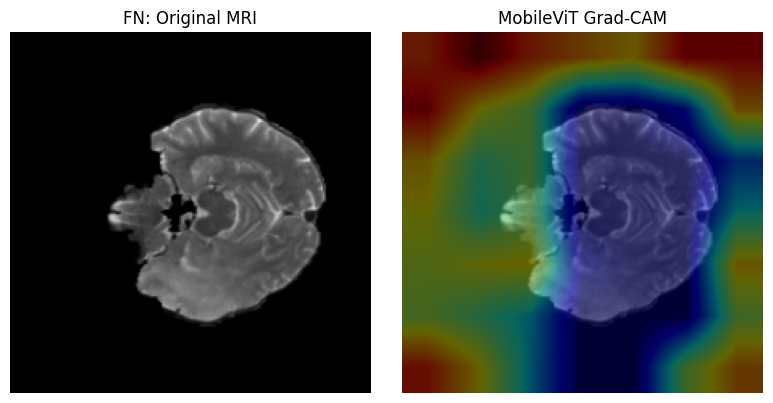

Saved CAM: /content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/XAI/FN_BraTS-GLI-01438-000_slice_54_cam.npy
Saved figure: /content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/XAI/FN_BraTS-GLI-01438-000_slice_54_gradcam.png


In [58]:

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

XAI_DIR = (
    "/content/drive/MyDrive/BrainTumor-Cloud-AI/"
    "reviewer_experiments/XAI"
)

patient_id = "BraTS-GLI-01438-000"
slice_id = 54

row = available_test[
    (available_test["patient_id"] == patient_id) &
    (available_test["slice_id"] == slice_id)
]

assert len(row) == 1, "Expected exactly one matching test record."

row = row.iloc[0]
image_path = row["colab_image_path"]

assert os.path.isfile(image_path), "MRI image is missing."
assert int(row["y_true"]) == 1, "Ground truth must be tumor-positive."

# Verify the current prediction before generating the explanation.
device = next(classifier_xai.parameters()).device
image = Image.open(image_path).convert("RGB")
x = transform(image).unsqueeze(0).to(device)

mobilevit_xai.eval()
swin_xai.eval()
classifier_xai.eval()

with torch.no_grad():
    mobile_features = mobilevit_xai(x)
    swin_features = swin_xai(x)
    fused_features = torch.cat(
        [mobile_features, swin_features], dim=1
    )
    logits = classifier_xai(fused_features)
    probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

current_pred = int(np.argmax(probs))
print("True label:", int(row["y_true"]))
print("Current prediction:", current_pred)
print("Current tumor probability:", float(probs[1]))

assert current_pred == 0, (
    "This case is not an FN under the current model. Stop here."
)

# Generate Grad-CAM for the predicted class (class 0).
original, cam, gradcam_probs, explained_class = (
    generate_mobilevit_gradcam(
        image_path,
        target_class=current_pred
    )
)

base = f"FN_{patient_id}_slice_{slice_id}"
cam_path = os.path.join(XAI_DIR, f"{base}_cam.npy")
figure_path = os.path.join(XAI_DIR, f"{base}_gradcam.png")

np.save(cam_path, cam)

original_display = np.asarray(original)
if original_display.ndim == 2:
    original_display = np.stack(
        [original_display] * 3, axis=-1
    )

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(original_display, cmap="gray")
axes[0].set_title("FN: Original MRI")
axes[0].axis("off")

axes[1].imshow(original_display, cmap="gray")
axes[1].imshow(cam, cmap="jet", alpha=0.40)
axes[1].set_title("MobileViT Grad-CAM")
axes[1].axis("off")

fig.tight_layout()
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved CAM:", cam_path)
print("Saved figure:", figure_path)


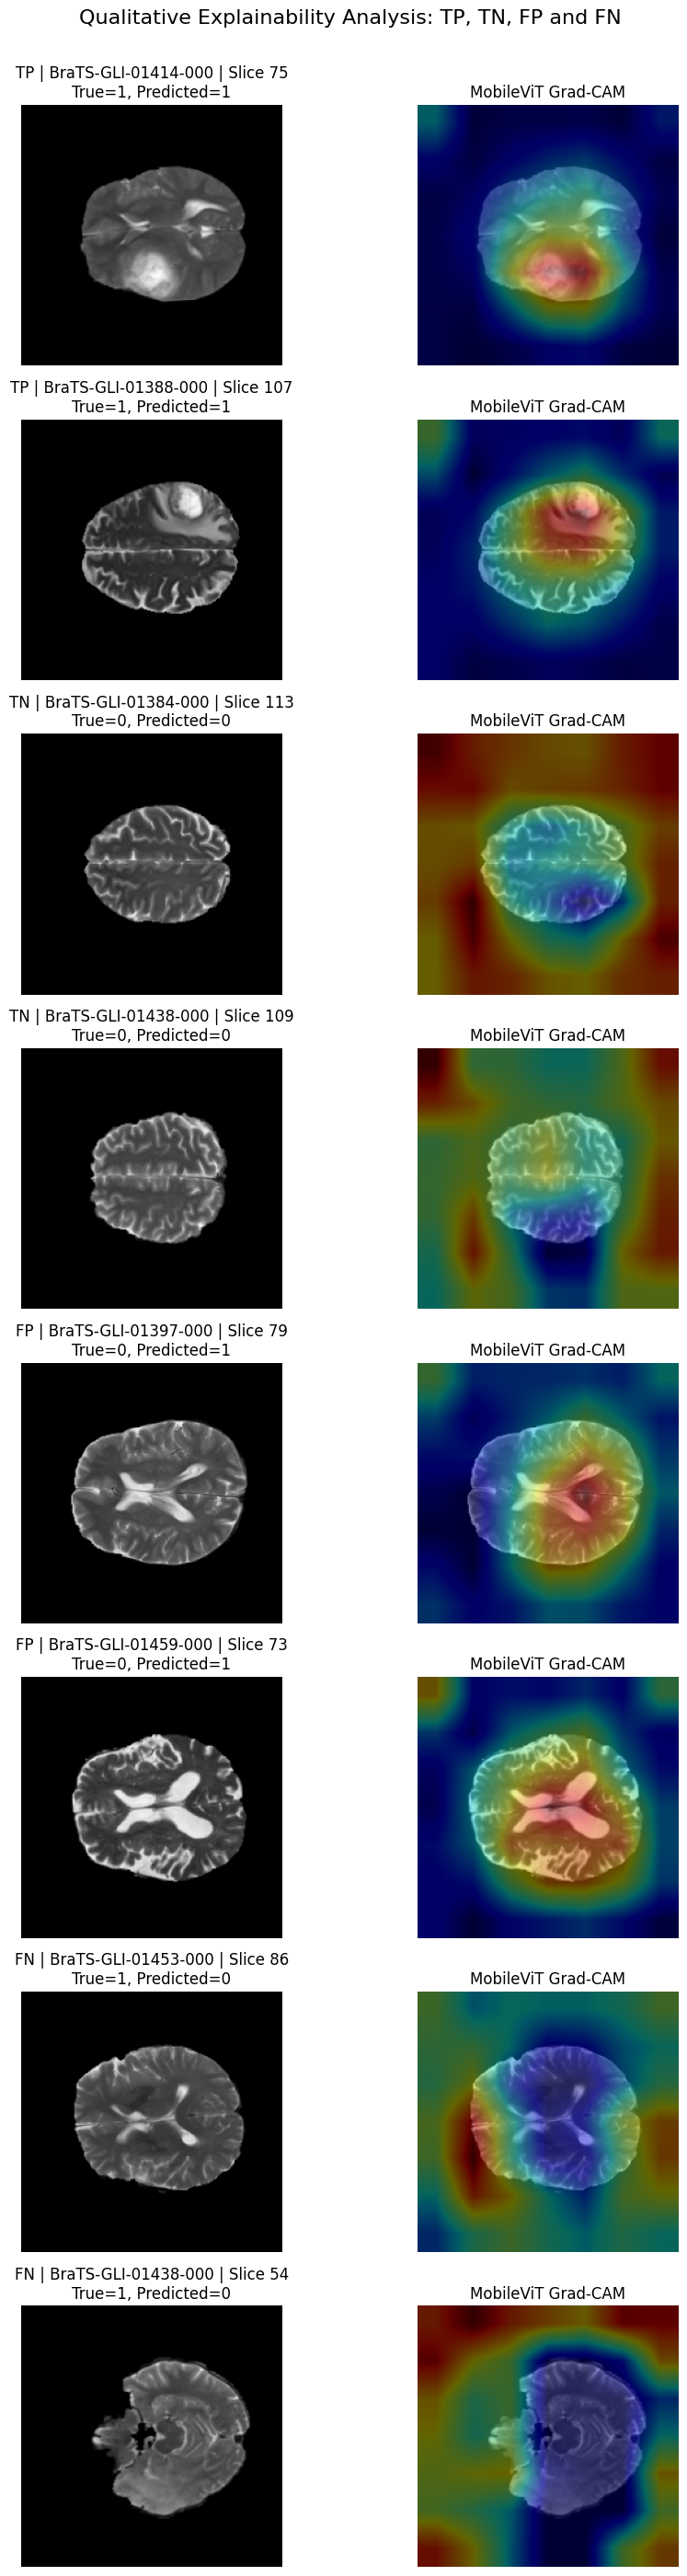

Figure saved: /content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/XAI/Figure_XAI_8_cases_final_v2.png
CSV saved: /content/drive/MyDrive/BrainTumor-Cloud-AI/reviewer_experiments/XAI/xai_8_cases_final_v2.csv

Case counts:
TP    2
TN    2
FP    2
FN    2
Name: count, dtype: int64

All cases passed current-model label checks.


In [59]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

XAI_DIR = (
    "/content/drive/MyDrive/BrainTumor-Cloud-AI/"
    "reviewer_experiments/XAI"
)

final_specs = [
    ("TP", "BraTS-GLI-01414-000", 75),
    ("TP", "BraTS-GLI-01388-000", 107),
    ("TN", "BraTS-GLI-01384-000", 113),
    ("TN", "BraTS-GLI-01438-000", 109),
    ("FP", "BraTS-GLI-01397-000", 79),
    ("FP", "BraTS-GLI-01459-000", 73),
    ("FN", "BraTS-GLI-01453-000", 86),
    ("FN", "BraTS-GLI-01438-000", 54),
]

# Load the current-model prediction for each selected case.
device = next(classifier_xai.parameters()).device
final_cases = []

for case_type, patient_id, slice_id in final_specs:
    rows = original_test[
        (original_test["patient_id"] == patient_id) &
        (original_test["slice_id"] == slice_id)
    ]
    if len(rows) != 1:
        raise ValueError(f"Metadata mismatch: {patient_id}, slice {slice_id}")

    row = rows.iloc[0]
    filename = str(row["image_path"]).replace("\\", "/").split("/")[-1]
    image_path = available_files.get(filename)

    if image_path is None or not os.path.isfile(image_path):
        raise FileNotFoundError(filename)

    expected_labels = {
        "TP": (1, 1), "TN": (0, 0),
        "FP": (0, 1), "FN": (1, 0)
    }
    actual_true = int(row["y_true"])
    if actual_true != expected_labels[case_type][0]:
        raise ValueError(f"Ground-truth mismatch: {patient_id}, slice {slice_id}")

    # Recompute the current model's prediction and probability.
    image_pil = Image.open(image_path).convert("RGB")
    x = transform(image_pil).unsqueeze(0).to(device)

    mobilevit_xai.eval()
    swin_xai.eval()
    classifier_xai.eval()

    with torch.no_grad():
        mf = mobilevit_xai(x)
        sf = swin_xai(x)
        logits = classifier_xai(torch.cat([mf, sf], dim=1))
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    current_pred = int(np.argmax(probs))
    if current_pred != expected_labels[case_type][1]:
        raise ValueError(
            f"Current prediction does not match {case_type} for "
            f"{patient_id}, slice {slice_id}. Prediction={current_pred}"
        )

    cam_path = os.path.join(
        XAI_DIR, f"{case_type}_{patient_id}_slice_{slice_id}_cam.npy"
    )
    if not os.path.isfile(cam_path):
        raise FileNotFoundError(f"Missing CAM: {cam_path}")

    final_cases.append({
        "case_type": case_type,
        "patient_id": patient_id,
        "slice_id": int(slice_id),
        "y_true": actual_true,
        "y_pred_current_model": current_pred,
        "prob_tumor_current_model": float(probs[1]),
        "image_path": image_path,
        "cam_path": cam_path,
    })

# Create final 8-case figure
fig, axes = plt.subplots(8, 2, figsize=(10, 28))

for i, case in enumerate(final_cases):
    image = np.asarray(Image.open(case["image_path"]).convert("RGB"))
    cam = np.load(case["cam_path"])

    if cam.shape != image.shape[:2]:
        cam_pil = Image.fromarray(
            np.uint8(np.clip(cam, 0, 1) * 255)
        ).resize(
            (image.shape[1], image.shape[0]),
            Image.Resampling.BILINEAR
        )
        cam = np.asarray(cam_pil, dtype=np.float32) / 255.0

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(
        f'{case["case_type"]} | {case["patient_id"]} | '
        f'Slice {case["slice_id"]}\n'
        f'True={case["y_true"]}, Predicted={case["y_pred_current_model"]}'
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(image)
    axes[i, 1].imshow(cam, cmap="jet", alpha=0.40, vmin=0, vmax=1)
    axes[i, 1].set_title("MobileViT Grad-CAM")
    axes[i, 1].axis("off")

fig.suptitle(
    "Qualitative Explainability Analysis: TP, TN, FP and FN",
    fontsize=16, y=0.998
)
fig.tight_layout(rect=[0, 0, 1, 0.994])

figure_path = os.path.join(XAI_DIR, "Figure_XAI_8_cases_final_v2.png")
csv_path = os.path.join(XAI_DIR, "xai_8_cases_final_v2.csv")

fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

pd.DataFrame(final_cases).to_csv(csv_path, index=False)

print("Figure saved:", figure_path)
print("CSV saved:", csv_path)
print("\nCase counts:")
print(pd.Series([c["case_type"] for c in final_cases]).value_counts())
print("\nAll cases passed current-model label checks.")


## Part B – Analyses executed on a CPU workstation from the Part A outputs


In [60]:
import json, math, time, platform
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.width', 200)
print('Python', platform.python_version())

Python 3.13.16


### B1. Component-wise ablation E1–E5 with 95% confidence intervals (Reviewer 2: comments 9, 10, 14, 15, 27; Experiment 2)


In [61]:
cms = {  # (TN, FP, FN, TP) on the case-disjoint test set (26,163 slices, 189 cases)
    'E1 MobileViT-S alone (640-d) + neural':   (11356, 2448, 2658, 9701),
    'E2 Swin-S alone (768-d) + neural':        (12221, 1583, 2298, 10061),
    'E3 MobileViT-S + Swin-S (1408-d) + neural': (12434, 1370, 2396, 9963),
    'E4 MobileViT-S + Swin-S + XGBoost':       (11833, 1971, 2020, 10339),
    'E5 MobileViT-S + Swin-S + XGBoost + TPE': (11854, 1950, 2024, 10335),
}
auroc = {'E1 MobileViT-S alone (640-d) + neural': 0.8935, 'E2 Swin-S alone (768-d) + neural': 0.9319,
         'E3 MobileViT-S + Swin-S (1408-d) + neural': 0.9373, 'E4 MobileViT-S + Swin-S + XGBoost': 0.9318,
         'E5 MobileViT-S + Swin-S + XGBoost + TPE': 0.9317}

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d
    h = z * math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return c - h, c + h

def hanley_se(A, n1, n0):
    q1 = A / (2 - A); q2 = 2*A*A / (1 + A)
    return math.sqrt((A*(1-A) + (n1-1)*(q1-A*A) + (n0-1)*(q2-A*A)) / (n1*n0))

rows = []
for k, (tn, fp, fn, tp) in cms.items():
    n = tn + fp + fn + tp; acc = (tp + tn) / n; sen = tp / (tp + fn); spe = tn / (tn + fp); pre = tp / (tp + fp)
    f1 = 2*pre*sen / (pre + sen); A = auroc[k]; se = hanley_se(A, tp + fn, tn + fp)
    a_lo, a_hi = wilson(tp + tn, n); s_lo, s_hi = wilson(tp, tp + fn); p_lo, p_hi = wilson(tn, tn + fp)
    rows.append({'Configuration': k, 'Accuracy %': f'{100*acc:.2f} [{100*a_lo:.2f}-{100*a_hi:.2f}]', 'Precision': f'{pre:.4f}',
                 'Sensitivity': f'{sen:.4f} [{s_lo:.4f}-{s_hi:.4f}]', 'Specificity': f'{spe:.4f} [{p_lo:.4f}-{p_hi:.4f}]',
                 'F1': f'{f1:.4f}', 'AUROC': f'{A:.4f} [{A-1.96*se:.4f}-{A+1.96*se:.4f}]'})
ablation = pd.DataFrame(rows)
display(ablation)

,Configuration,Accuracy %,Precision,Sensitivity,Specificity,F1,AUROC
0,E1 MobileViT-S alone (640-d) + neural,80.48 [80.00-80.96],0.7985,0.7849 [0.7776-0.7921],0.8227 [0.8162-0.8289],0.7917,0.8935 [0.8894-0.8976]
1,E2 Swin-S alone (768-d) + neural,85.17 [84.73-85.59],0.8641,0.8141 [0.8071-0.8208],0.8853 [0.8799-0.8905],0.8383,0.9319 [0.9286-0.9352]
2,E3 MobileViT-S + Swin-S (1408-d) + neural,85.61 [85.18-86.03],0.8791,0.8061 [0.7991-0.8130],0.9008 [0.8957-0.9056],0.8410,0.9373 [0.9342-0.9404]
3,E4 MobileViT-S + Swin-S + XGBoost,84.75 [84.30-85.18],0.8399,0.8366 [0.8299-0.8430],0.8572 [0.8513-0.8630],0.8382,0.9318 [0.9285-0.9351]
4,E5 MobileViT-S + Swin-S + XGBoost + TPE,84.81 [84.37-85.24],0.8413,0.8362 [0.8296-0.8427],0.8587 [0.8528-0.8644],0.8387,0.9317 [0.9284-0.9350]


### B2. Class-wise results and confusion patterns (Reviewer 2: comment 27)

In [62]:
cw = []
for k, (tn, fp, fn, tp) in cms.items():
    npv = tn/(tn+fn); spe = tn/(tn+fp); f0 = 2*npv*spe/(npv+spe)
    ppv = tp/(tp+fp); sen = tp/(tp+fn); f1 = 2*ppv*sen/(ppv+sen)
    cw.append({'Configuration': k.split(' ')[0], 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
               'Tumor-free P/R/F1': f'{npv:.4f} / {spe:.4f} / {f0:.4f}', 'Tumor P/R/F1': f'{ppv:.4f} / {sen:.4f} / {f1:.4f}',
               'Macro F1': round((f0+f1)/2, 4)})
display(pd.DataFrame(cw))

,Configuration,TN,FP,FN,TP,Tumor-free P/R/F1,Tumor P/R/F1,Macro F1
0,E1,11356,2448,2658,9701,0.8103 / 0.8227 / 0.8164,0.7985 / 0.7849 / 0.7917,0.8041
1,E2,12221,1583,2298,10061,0.8417 / 0.8853 / 0.8630,0.8641 / 0.8141 / 0.8383,0.8506
2,E3,12434,1370,2396,9963,0.8384 / 0.9008 / 0.8685,0.8791 / 0.8061 / 0.8410,0.8548
3,E4,11833,1971,2020,10339,0.8542 / 0.8572 / 0.8557,0.8399 / 0.8366 / 0.8382,0.8470
4,E5,11854,1950,2024,10335,0.8542 / 0.8587 / 0.8564,0.8413 / 0.8362 / 0.8387,0.8476


### B3. Five-seed summary of E3 (Reviewer 2: comments 14, 15) – values from Part A cell A-SEEDS

In [63]:
seeds = pd.DataFrame({
 'seed': [42, 123, 2024, 3407, 9999],
 'accuracy': [0.858885, 0.854910, 0.858655, 0.854336, 0.854795],
 'precision': [0.880499, 0.835672, 0.864428, 0.891823, 0.838073],
 'sensitivity': [0.811393, 0.862448, 0.831135, 0.787119, 0.858484],
 'specificity': [0.901405, 0.848160, 0.883295, 0.914518, 0.851492],
 'f1': [0.844534, 0.848849, 0.847455, 0.836206, 0.848155],
 'auroc': [0.939128, 0.939278, 0.939100, 0.938041, 0.938952]})
display(seeds.round(4))
summ = seeds.drop(columns='seed').agg(['mean', 'std']).T
summ['mean ± SD'] = summ.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1)
display(summ[['mean ± SD']])

,seed,accuracy,precision,sensitivity,specificity,f1,auroc
0,42,0.8589,0.8805,0.8114,0.9014,0.8445,0.9391
1,123,0.8549,0.8357,0.8624,0.8482,0.8488,0.9393
2,2024,0.8587,0.8644,0.8311,0.8833,0.8475,0.9391
3,3407,0.8543,0.8918,0.7871,0.9145,0.8362,0.9380
4,9999,0.8548,0.8381,0.8585,0.8515,0.8482,0.9390


,mean ± SD
accuracy,0.8563 ± 0.0023
precision,0.8621 ± 0.0250
sensitivity,0.8301 ± 0.0318
specificity,0.8798 ± 0.0295
f1,0.8450 ± 0.0052
auroc,0.9389 ± 0.0005


### B4. Complexity and CPU latency against lightweight single-backbone models (Reviewer 2: comments 16, 17, 18)
Parameters, MACs (PyTorch FLOP counter, MACs = FLOPs/2), FP32 size and CPU latency (batch 1, 2 threads, 40 timed runs after
8 warm-up runs) for a 224 × 224 input.

In [64]:
import torch, timm
from torch.utils.flop_counter import FlopCounterMode
torch.set_num_threads(2); torch.manual_seed(0)
cpu = open('/proc/cpuinfo').read().split('model name')[1].split('\n')[0].strip(': ')
print('CPU:', cpu, '| threads:', torch.get_num_threads(), '| torch', torch.__version__, '| timm', timm.__version__)
x = torch.randn(1, 3, 224, 224)
def macs(m):
    with FlopCounterMode(display=False) as fc:
        with torch.no_grad(): m(x)
    return fc.get_total_flops() / 2
def lat(f, n=40, warm=8):
    for _ in range(warm): f()
    t = []
    for _ in range(n):
        s = time.perf_counter(); f(); t.append((time.perf_counter() - s) * 1000)
    return np.mean(t), np.std(t)
names = {'MobileNetV3-Large': 'mobilenetv3_large_100', 'EfficientNet-B0': 'efficientnet_b0', 'DeiT-Tiny': 'deit_tiny_patch16_224',
         'MobileViT-XS': 'mobilevit_xs', 'MobileViT-S': 'mobilevit_s', 'ResNet-18': 'resnet18', 'ViT-S/16': 'vit_small_patch16_224',
         'Swin-S': 'swin_small_patch4_window7_224', 'Swin-B': 'swin_base_patch4_window7_224'}
models, bench = {}, []
for k, v in names.items():
    m = timm.create_model(v, pretrained=False, num_classes=0).eval(); models[k] = m
    p = sum(q.numel() for q in m.parameters())
    with torch.no_grad(): d = m(x).shape[1]; mu, sd = lat(lambda: m(x))
    bench.append({'Model': k, 'Params (M)': p/1e6, 'GMACs': macs(m)/1e9, 'Size (MB)': p*4/2**20, 'Embedding': d, 'CPU ms': mu, 'CPU sd': sd})
for k, (a, b) in {'ResNet-18 + ViT-S/16': ('ResNet-18', 'ViT-S/16'), 'MobileViT-S + Swin-B': ('MobileViT-S', 'Swin-B'),
                  'MobileViT-S + Swin-S (DC-ViT)': ('MobileViT-S', 'Swin-S')}.items():
    A, B = models[a], models[b]
    def f():
        with torch.no_grad(): return torch.cat([A(x), B(x)], 1)
    mu, sd = lat(f); ra = next(r for r in bench if r['Model'] == a); rb = next(r for r in bench if r['Model'] == b)
    bench.append({'Model': k, 'Params (M)': ra['Params (M)'] + rb['Params (M)'], 'GMACs': ra['GMACs'] + rb['GMACs'],
                  'Size (MB)': ra['Size (MB)'] + rb['Size (MB)'], 'Embedding': ra['Embedding'] + rb['Embedding'], 'CPU ms': mu, 'CPU sd': sd})
bench = pd.DataFrame(bench); display(bench.round(2))

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CPU: 	: Intel(R) Xeon(R) Processor @ 2.80GHz | threads: 2 | torch 2.14.1+cu130 | timm 1.0.30


,Model,Params (M),GMACs,Size (MB),Embedding,CPU ms,CPU sd
0,MobileNetV3-Large,4.20,0.22,16.03,1280,24.73,3.28
1,EfficientNet-B0,4.01,0.38,15.29,1280,43.98,8.21
2,DeiT-Tiny,5.52,1.07,21.07,192,33.92,5.30
3,MobileViT-XS,1.93,0.70,7.37,384,52.72,15.61
4,MobileViT-S,4.94,1.42,18.84,640,73.38,10.24
5,ResNet-18,11.18,1.81,42.64,512,46.66,5.08
6,ViT-S/16,21.67,4.24,82.65,384,81.03,10.73
7,Swin-S,48.84,8.74,186.30,768,238.82,14.31
8,Swin-B,86.74,15.43,330.90,1024,370.73,25.41
9,ResNet-18 + ViT-S/16,32.84,6.05,125.28,896,126.21,11.58


In [65]:
# Classifier-head CPU latency (neural head and XGBoost forests of the trained sizes)
import xgboost as xgb
head = torch.nn.Sequential(torch.nn.Linear(1408, 256), torch.nn.ReLU(), torch.nn.Dropout(0.3), torch.nn.Linear(256, 2)).eval()
z = torch.randn(1, 1408)
with torch.no_grad(): mu, sd = lat(lambda: head(z), n=500, warm=50)
print(f'Neural head: {sum(p.numel() for p in head.parameters()):,} params, CPU {mu:.3f} ± {sd:.3f} ms/slice')
rng = np.random.default_rng(0); Xs = rng.normal(size=(20000, 1408)).astype(np.float32); ys = (Xs[:, :20].sum(1) + rng.normal(size=20000) > 0).astype(int)
for name, prm in {'XGBoost fixed (600 trees, depth 8)': dict(n_estimators=600, max_depth=8, learning_rate=0.03),
                  'XGBoost TPE (587 trees, depth 5)': dict(n_estimators=587, max_depth=5, learning_rate=0.0767)}.items():
    mdl = xgb.XGBClassifier(**prm, tree_method='hist', n_jobs=2, random_state=42).fit(Xs, ys)
    mu, sd = lat(lambda: mdl.predict_proba(Xs[:1]), n=200, warm=20)
    print(f'{name}: CPU {mu:.3f} ± {sd:.3f} ms/slice')

Neural head: 361,218 params, CPU 0.075 ± 0.065 ms/slice


XGBoost fixed (600 trees, depth 8): CPU 0.404 ± 0.327 ms/slice


XGBoost TPE (587 trees, depth 5): CPU 0.326 ± 0.059 ms/slice


### B5. Figures used in the manuscript (Figures 2 and 3)

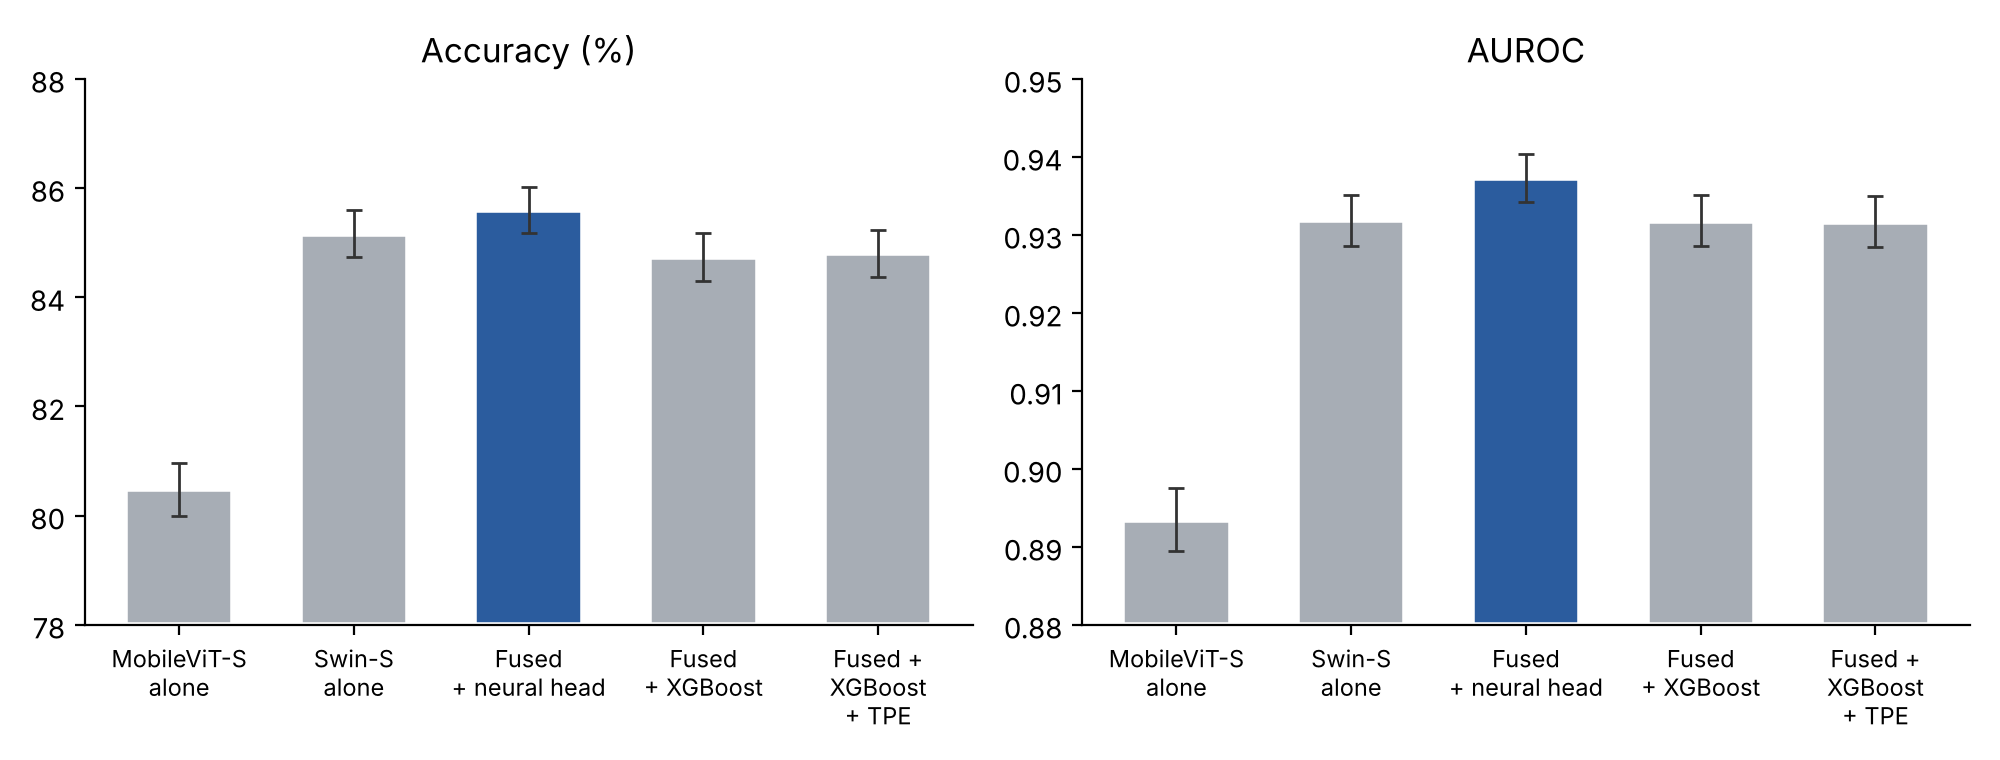

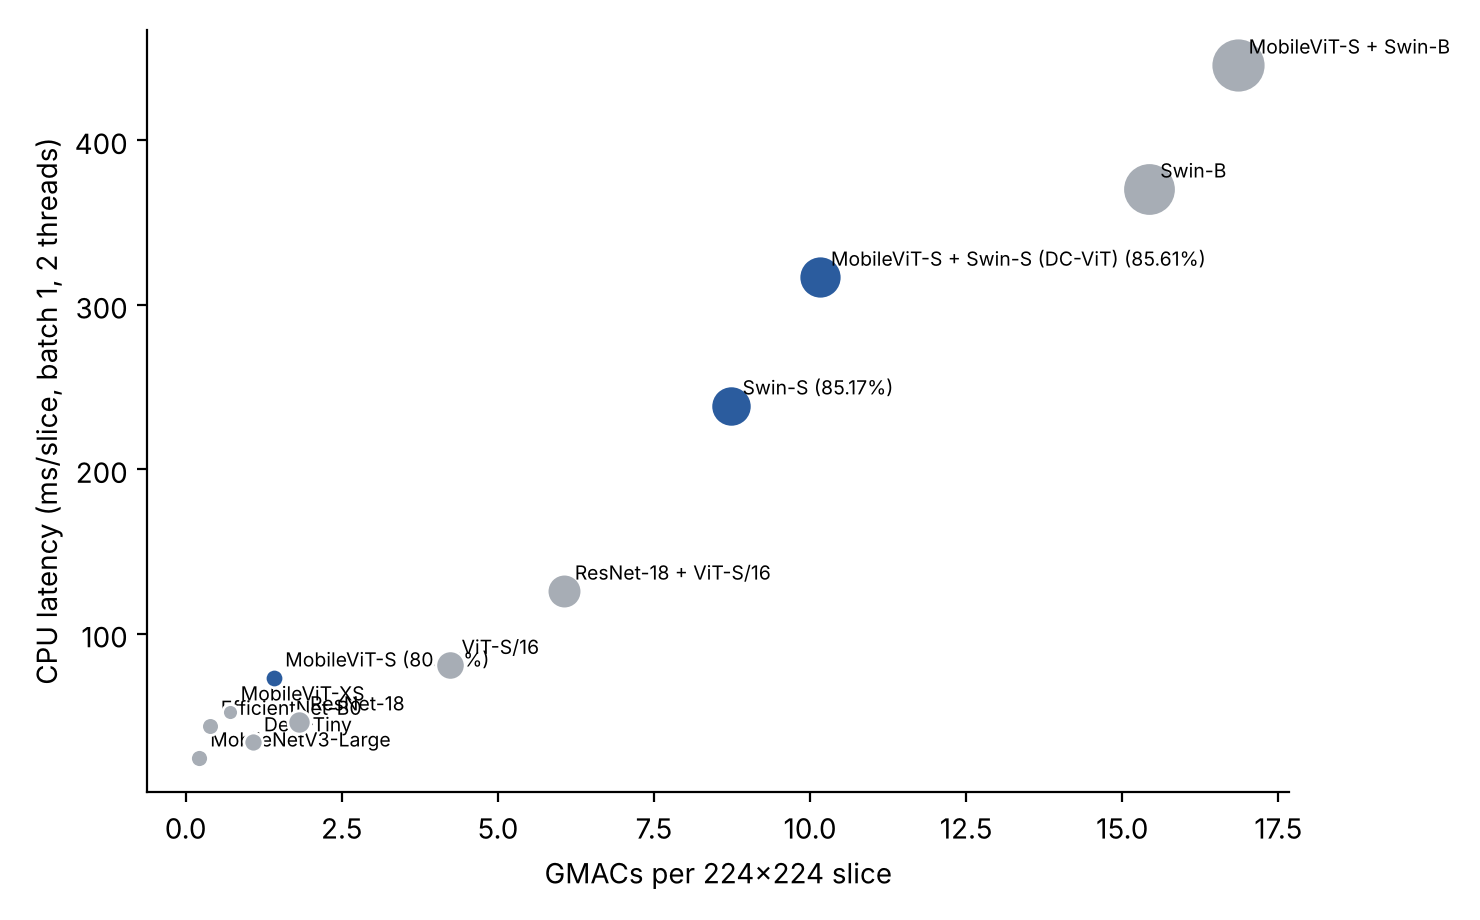

In [66]:
BLUE, GRAY = '#2B5C9E', '#A7ADB5'
labels = ['MobileViT-S\nalone', 'Swin-S\nalone', 'Fused\n+ neural head', 'Fused\n+ XGBoost', 'Fused +\nXGBoost\n+ TPE']
keys = list(cms)
acc = [100*(cms[k][0]+cms[k][3])/sum(cms[k]) for k in keys]
acc_ci = [wilson(cms[k][0]+cms[k][3], sum(cms[k])) for k in keys]
au = [auroc[k] for k in keys]; au_se = [hanley_se(auroc[k], cms[k][2]+cms[k][3], cms[k][0]+cms[k][1]) for k in keys]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, v, lo, hi, ttl, ylim in [(ax[0], acc, [100*c[0] for c in acc_ci], [100*c[1] for c in acc_ci], 'Accuracy (%)', (78, 88)),
                                (ax[1], au, [u-1.96*s for u, s in zip(au, au_se)], [u+1.96*s for u, s in zip(au, au_se)], 'AUROC', (0.88, 0.95))]:
    a.bar(range(5), [x-ylim[0] for x in v], bottom=ylim[0], color=[GRAY, GRAY, BLUE, GRAY, GRAY], width=0.62, edgecolor='white', linewidth=2)
    a.errorbar(range(5), v, yerr=[[x-l for x, l in zip(v, lo)], [h-x for x, h in zip(v, hi)]], fmt='none', ecolor='#333', capsize=3, lw=1)
    a.set_xticks(range(5)); a.set_xticklabels(labels, fontsize=8.5); a.set_title(ttl); a.set_ylim(*ylim)
    for s in ['top', 'right']: a.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig('Figure2_ablation.png', dpi=200); plt.close()
display(Image('Figure2_ablation.png'))
fig, a = plt.subplots(figsize=(7.4, 4.6))
ev = {'MobileViT-S': 80.48, 'Swin-S': 85.17, 'MobileViT-S + Swin-S (DC-ViT)': 85.61}
for _, r in bench.iterrows():
    a.scatter(r['GMACs'], r['CPU ms'], s=25 + 4*r['Params (M)'], color=BLUE if r['Model'] in ev else GRAY, edgecolor='white', zorder=3)
    a.annotate(r['Model'] + (f" ({ev[r['Model']]:.2f}%)" if r['Model'] in ev else ''), (r['GMACs'], r['CPU ms']), fontsize=7, xytext=(4, 4), textcoords='offset points')
a.set_xlabel('GMACs per 224×224 slice'); a.set_ylabel('CPU latency (ms/slice, batch 1, 2 threads)')
for s in ['top', 'right']: a.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig('Figure3_complexity.png', dpi=200); plt.close()
display(Image('Figure3_complexity.png'))

### B6. Consolidated consistency check of the eight Grad-CAM examples (R1-3, R2-21) – values printed by the Grad-CAM checkpoint in cells A10

In [67]:
import pandas as pd
# Probabilities of the tumor class printed by the single-run E3 checkpoint (Part A, cell A10 outputs)
xai = pd.DataFrame([
    ('TP', 'BraTS-GLI-01414-000',  75, 1, 1.000000),
    ('TP', 'BraTS-GLI-01388-000', 107, 1, 0.999995),
    ('TN', 'BraTS-GLI-01384-000', 113, 0, 0.066147),
    ('TN', 'BraTS-GLI-01438-000', 109, 0, 0.063877),
    ('FP', 'BraTS-GLI-01397-000',  79, 0, 0.954310),
    ('FP', 'BraTS-GLI-01459-000',  73, 0, 0.975904),
    ('FN', 'BraTS-GLI-01453-000',  86, 1, 0.488975),
    ('FN', 'BraTS-GLI-01438-000',  54, 1, 0.382883),
], columns=['case_type', 'case_id', 'slice', 'y_true', 'p_tumor_gradcam_model'])
xai['y_pred'] = (xai['p_tumor_gradcam_model'] >= 0.5).astype(int)
expected = {'TP': (1, 1), 'TN': (0, 0), 'FP': (0, 1), 'FN': (1, 0)}
xai['consistent'] = [(r.y_true, r.y_pred) == expected[r.case_type] for r in xai.itertuples()]
display(xai)
assert xai['consistent'].all(), 'inconsistent Grad-CAM example'
assert xai.groupby('case_type').size().eq(2).all()
print('All eight Grad-CAM examples are consistent with the explained model (2 TP, 2 TN, 2 FP, 2 FN).')
print('Cases with TP/TN/FP/FN examples:', xai.case_id.nunique(), 'distinct case identifiers')

,case_type,case_id,slice,y_true,p_tumor_gradcam_model,y_pred,consistent
0,TP,BraTS-GLI-01414-000,75,1,1.000000,1,True
1,TP,BraTS-GLI-01388-000,107,1,0.999995,1,True
2,TN,BraTS-GLI-01384-000,113,0,0.066147,0,True
3,TN,BraTS-GLI-01438-000,109,0,0.063877,0,True
4,FP,BraTS-GLI-01397-000,79,0,0.954310,1,True
5,FP,BraTS-GLI-01459-000,73,0,0.975904,1,True
6,FN,BraTS-GLI-01453-000,86,1,0.488975,0,True
7,FN,BraTS-GLI-01438-000,54,1,0.382883,0,True


All eight Grad-CAM examples are consistent with the explained model (2 TP, 2 TN, 2 FP, 2 FN).
Cases with TP/TN/FP/FN examples: 7 distinct case identifiers


### B7. TPE search protocol and observed outcome, trial by trial (Reviewer 2: comments 12 and 13; Table 2)
The Optuna log printed by the executed Colab cell in Section A7 (study creation and all 30 `Trial … finished` lines) is parsed below to report, for each trial, the validation accuracy, the best value so far and the duration. The default sampler and pruner are read from the same Optuna version (5.0.0) with the same `optuna.create_study(direction="maximize")` call. These values fill the last column of Table 2 in the manuscript. The test set is not used in this cell.

,trial,phase,val_acc,best_so_far,duration_s,n_estimators,max_depth,learning_rate
0,0,random start-up (trials 0-9),0.8524,0.8524,80.406,658,7,0.0757
1,1,random start-up (trials 0-9),0.8402,0.8524,53.494,362,4,0.0239
2,2,random start-up (trials 0-9),0.8470,0.8524,54.519,266,5,0.0445
3,3,random start-up (trials 0-9),0.8480,0.8524,61.583,660,4,0.0231
4,4,random start-up (trials 0-9),0.8516,0.8524,56.351,289,6,0.0780
5,5,random start-up (trials 0-9),0.8504,0.8524,61.725,379,6,0.0485
6,6,random start-up (trials 0-9),0.8456,0.8524,51.408,215,5,0.0587
7,7,random start-up (trials 0-9),0.8500,0.8524,59.426,601,4,0.0352
8,8,random start-up (trials 0-9),0.8530,0.8530,63.410,604,5,0.0717
9,9,random start-up (trials 0-9),0.8528,0.8530,63.894,616,5,0.0712


Optuna version              : 5.0.0
Sampler / pruner (default)  : TPESampler / MedianPruner
n_startup_trials            : 10
n_ei_candidates             : 24
multivariate TPE            : True
sampler seed                : not set (seed=None)
pruning in objective        : objective calls neither trial.report() nor trial.should_prune(), so the default pruner cannot stop any trial


,Quantity,Value
0,Trials completed / pruned / failed,30 / 0 / 0
1,Best trial (validation accuracy),trial 13 (0.8569)
2,Gap to 2nd-best trial,0.0009
3,"Validation accuracy, all trials",0.8522 ± 0.0034 (range 0.8402–0.8569)
4,Mean val. accuracy: start-up vs TPE phase,0.8491 vs 0.8537
5,Trial duration (s),mean 62.2 ± 5.8; median 61.9; range 51.4–80.4
6,Total search time from log (s),1866.1 (Colab timer: 1866.11 s)
7,Refit of best configuration (s),57.71 (training set only)
8,Data,"fit 121,737 train slices; score 26,126 validat..."


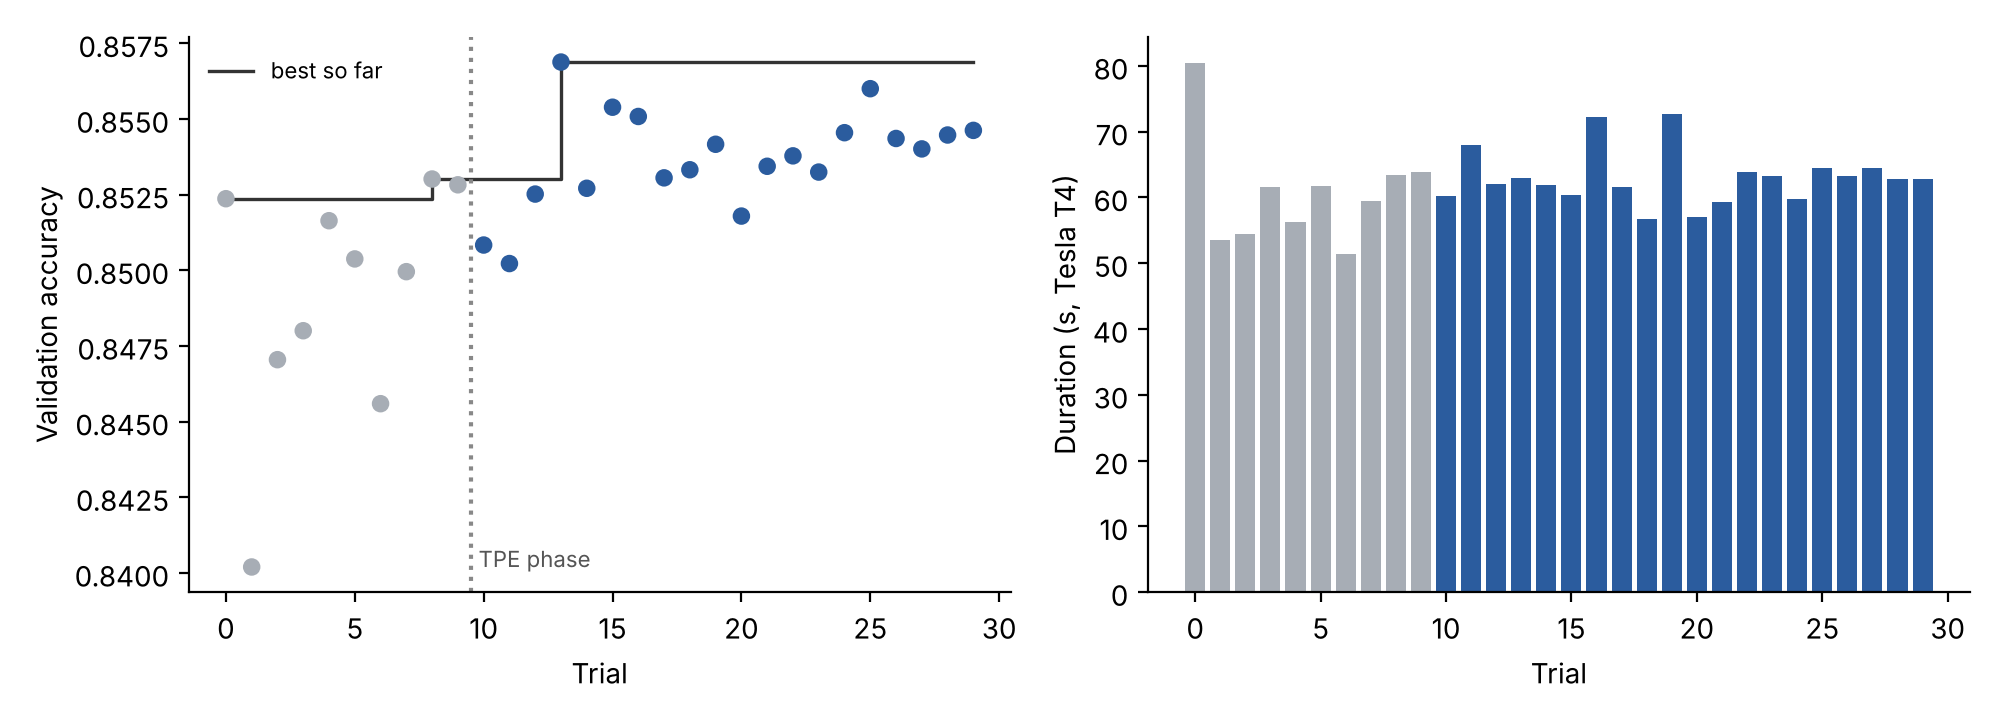

In [68]:
import warnings; warnings.filterwarnings('ignore')
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from datetime import datetime
from IPython.display import Image, display

# Optuna log of the E5 TPE study, copied verbatim from the executed Colab cell in Section A7
TPE_LOG = """[I 2026-10-08 14:01:13,415] A new study created in memory with name: no-name-229bf91d-4c61-4588-b2da-9b2f0fbcef0e
  0%|          | 0/30 [00:00<?, ?it/s][I 2026-10-08 14:02:33,821] Trial 0 finished with value: 0.8523692873000076 and parameters: {'n_estimators': 658, 'max_depth': 7, 'learning_rate': 0.07574042221262, 'subsample': 0.7364165999070283, 'colsample_bytree': 0.6732884263855513, 'min_child_weight': 6, 'gamma': 0.003659606952414518, 'reg_alpha': 0.07840880335327208, 'reg_lambda': 0.9471274983077679}. Best is trial 0 with value: 0.8523692873000076.
[I 2026-10-08 14:03:27,315] Trial 1 finished with value: 0.8401975044017453 and parameters: {'n_estimators': 362, 'max_depth': 4, 'learning_rate': 0.02385520533990615, 'subsample': 0.8496803751268724, 'colsample_bytree': 0.703757204106904, 'min_child_weight': 2, 'gamma': 0.03797196033928891, 'reg_alpha': 0.28774983666229437, 'reg_lambda': 0.9281669075438244}. Best is trial 0 with value: 0.8523692873000076.
[I 2026-10-08 14:04:21,834] Trial 2 finished with value: 0.8470489167878742 and parameters: {'n_estimators': 266, 'max_depth': 5, 'learning_rate': 0.04454794538854628, 'subsample': 0.8734671959962681, 'colsample_bytree': 0.7268854252110316, 'min_child_weight': 2, 'gamma': 0.274878480967153, 'reg_alpha': 0.2626309713953998, 'reg_lambda': 1.108546046124269}. Best is trial 0 with value: 0.8523692873000076.
[I 2026-10-08 14:05:23,417] Trial 3 finished with value: 0.8480058179591212 and parameters: {'n_estimators': 660, 'max_depth': 4, 'learning_rate': 0.0230925024947186, 'subsample': 0.6939550058658003, 'colsample_bytree': 0.6576268460167369, 'min_child_weight': 6, 'gamma': 0.11194002942342059, 'reg_alpha': 0.2269057860233923, 'reg_lambda': 1.2943791523821042}. Best is trial 0 with value: 0.8523692873000076.
[I 2026-10-08 14:06:19,768] Trial 4 finished with value: 0.8516420424098599 and parameters: {'n_estimators': 289, 'max_depth': 6, 'learning_rate': 0.07800957559282606, 'subsample': 0.6045143224385394, 'colsample_bytree': 0.6475348183982096, 'min_child_weight': 4, 'gamma': 0.2411372708325699, 'reg_alpha': 0.2311838582270809, 'reg_lambda': 0.9449907602695713}. Best is trial 0 with value: 0.8523692873000076.
[I 2026-10-08 14:07:21,493] Trial 5 finished with value: 0.8503789328638138 and parameters: {'n_estimators': 379, 'max_depth': 6, 'learning_rate': 0.04849793987386175, 'subsample': 0.8598447100544846, 'colsample_bytree': 0.7322648851616465, 'min_child_weight': 3, 'gamma': 0.26978207202923493, 'reg_alpha': 0.275160449852872, 'reg_lambda': 0.5369103560761319}. Best is trial 0 with value: 0.8523692873000076.
[I 2026-10-08 14:08:12,901] Trial 6 finished with value: 0.8455944270075787 and parameters: {'n_estimators': 215, 'max_depth': 5, 'learning_rate': 0.058660233037644165, 'subsample': 0.6906600475015172, 'colsample_bytree': 0.7895028706720137, 'min_child_weight': 5, 'gamma': 0.12152430750286793, 'reg_alpha': 0.04080718786280413, 'reg_lambda': 1.429204065605987}. Best is trial 0 with value: 0.8523692873000076.
[I 2026-10-08 14:09:12,327] Trial 7 finished with value: 0.8499578963484651 and parameters: {'n_estimators': 601, 'max_depth': 4, 'learning_rate': 0.0352230946244081, 'subsample': 0.7110276376933603, 'colsample_bytree': 0.8225783982378836, 'min_child_weight': 1, 'gamma': 0.11989921540667414, 'reg_alpha': 0.16180700966661635, 'reg_lambda': 1.2562569918986337}. Best is trial 0 with value: 0.8523692873000076.
[I 2026-10-08 14:10:15,737] Trial 8 finished with value: 0.8530199800964556 and parameters: {'n_estimators': 604, 'max_depth': 5, 'learning_rate': 0.07166975916537466, 'subsample': 0.6272089643229558, 'colsample_bytree': 0.8010634203808837, 'min_child_weight': 2, 'gamma': 0.23864099953218684, 'reg_alpha': 0.19326271633578992, 'reg_lambda': 1.3858925639090365}. Best is trial 8 with value: 0.8530199800964556.
[I 2026-10-08 14:11:19,631] Trial 9 finished with value: 0.8528285998622063 and parameters: {'n_estimators': 616, 'max_depth': 5, 'learning_rate': 0.07122690551418032, 'subsample': 0.7055084590905456, 'colsample_bytree': 0.8907115865348203, 'min_child_weight': 6, 'gamma': 0.21148329517831296, 'reg_alpha': 0.04152876733798603, 'reg_lambda': 1.533152852310472}. Best is trial 8 with value: 0.8530199800964556.
[I 2026-10-08 14:12:19,862] Trial 10 finished with value: 0.8508382454260124 and parameters: {'n_estimators': 592, 'max_depth': 4, 'learning_rate': 0.044643319454815054, 'subsample': 0.6852742672946239, 'colsample_bytree': 0.8225899164283855, 'min_child_weight': 4, 'gamma': 0.23435940776316286, 'reg_alpha': 0.14980521169407665, 'reg_lambda': 1.3378519049138327}. Best is trial 8 with value: 0.8530199800964556.
[I 2026-10-08 14:13:27,870] Trial 11 finished with value: 0.8502258286764143 and parameters: {'n_estimators': 522, 'max_depth': 6, 'learning_rate': 0.07983897369997266, 'subsample': 0.6907150526722143, 'colsample_bytree': 0.840842529422304, 'min_child_weight': 4, 'gamma': 0.2919838604510101, 'reg_alpha': 0.1774788694596949, 'reg_lambda': 1.6566139032030684}. Best is trial 8 with value: 0.8530199800964556.
[I 2026-10-08 14:14:29,893] Trial 12 finished with value: 0.8525223914874072 and parameters: {'n_estimators': 502, 'max_depth': 5, 'learning_rate': 0.07418401702168673, 'subsample': 0.7149289368689035, 'colsample_bytree': 0.8750691734595285, 'min_child_weight': 4, 'gamma': 0.16827957797203205, 'reg_alpha': 0.11334469801436492, 'reg_lambda': 1.440683617844125}. Best is trial 8 with value: 0.8530199800964556.
[I 2026-10-08 14:15:32,875] Trial 13 finished with value: 0.8568858608282937 and parameters: {'n_estimators': 587, 'max_depth': 5, 'learning_rate': 0.0767120212537076, 'subsample': 0.6516342092487915, 'colsample_bytree': 0.7583155570513979, 'min_child_weight': 6, 'gamma': 0.2591497402075088, 'reg_alpha': 0.10574895083781113, 'reg_lambda': 1.2405270288782524}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:16:34,711] Trial 14 finished with value: 0.8527137717216566 and parameters: {'n_estimators': 516, 'max_depth': 5, 'learning_rate': 0.07485857308701943, 'subsample': 0.6122648770026204, 'colsample_bytree': 0.7752751766940901, 'min_child_weight': 3, 'gamma': 0.28757919856218006, 'reg_alpha': 0.12927053072647193, 'reg_lambda': 1.2209202747731565}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:17:35,119] Trial 15 finished with value: 0.8553930950011482 and parameters: {'n_estimators': 694, 'max_depth': 4, 'learning_rate': 0.07846538060120213, 'subsample': 0.6331323830060845, 'colsample_bytree': 0.6993460839987727, 'min_child_weight': 6, 'gamma': 0.26682930099064245, 'reg_alpha': 0.14231901594294846, 'reg_lambda': 1.6483047221422633}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:18:47,316] Trial 16 finished with value: 0.8550868866263492 and parameters: {'n_estimators': 683, 'max_depth': 6, 'learning_rate': 0.07518736428173395, 'subsample': 0.6972515191168305, 'colsample_bytree': 0.6803778050431926, 'min_child_weight': 5, 'gamma': 0.21645468401241744, 'reg_alpha': 0.05050317327649059, 'reg_lambda': 1.6647929644932444}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:19:48,945] Trial 17 finished with value: 0.8530582561433055 and parameters: {'n_estimators': 651, 'max_depth': 4, 'learning_rate': 0.07499100308939469, 'subsample': 0.633410214088499, 'colsample_bytree': 0.7323234359845219, 'min_child_weight': 5, 'gamma': 0.2515003367585786, 'reg_alpha': 0.16885489968683268, 'reg_lambda': 1.5328767733439463}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:20:45,612] Trial 18 finished with value: 0.8533261884712547 and parameters: {'n_estimators': 530, 'max_depth': 4, 'learning_rate': 0.07225701587464156, 'subsample': 0.6538832256431558, 'colsample_bytree': 0.7715702710596065, 'min_child_weight': 6, 'gamma': 0.22521144353496492, 'reg_alpha': 0.07476580988730927, 'reg_lambda': 1.499412071523898}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:21:58,352] Trial 19 finished with value: 0.8541682615019521 and parameters: {'n_estimators': 674, 'max_depth': 6, 'learning_rate': 0.07144591554939765, 'subsample': 0.6200951316999106, 'colsample_bytree': 0.7638512605013804, 'min_child_weight': 6, 'gamma': 0.1841046341574403, 'reg_alpha': 0.16400675428624684, 'reg_lambda': 1.0860207211458652}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:22:55,325] Trial 20 finished with value: 0.8517951465972594 and parameters: {'n_estimators': 537, 'max_depth': 4, 'learning_rate': 0.06622416784126924, 'subsample': 0.6353367586927936, 'colsample_bytree': 0.667878093739888, 'min_child_weight': 6, 'gamma': 0.2192157922139403, 'reg_alpha': 0.09995420959932716, 'reg_lambda': 1.9750006027397073}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:23:54,619] Trial 21 finished with value: 0.8534410166118044 and parameters: {'n_estimators': 610, 'max_depth': 4, 'learning_rate': 0.0656718963469578, 'subsample': 0.6845734981369608, 'colsample_bytree': 0.7172918345779261, 'min_child_weight': 6, 'gamma': 0.2429298153464291, 'reg_alpha': 0.15786348279102205, 'reg_lambda': 1.1697414624723907}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:24:58,523] Trial 22 finished with value: 0.8537855010334533 and parameters: {'n_estimators': 642, 'max_depth': 5, 'learning_rate': 0.07905641335949012, 'subsample': 0.6594086230044511, 'colsample_bytree': 0.6881524431557792, 'min_child_weight': 6, 'gamma': 0.29588794084746733, 'reg_alpha': 0.05840723467578826, 'reg_lambda': 1.0290275368319588}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:26:01,837] Trial 23 finished with value: 0.8532496363775549 and parameters: {'n_estimators': 654, 'max_depth': 5, 'learning_rate': 0.0771497344286494, 'subsample': 0.6846955250756812, 'colsample_bytree': 0.6545531313977377, 'min_child_weight': 6, 'gamma': 0.281408583342158, 'reg_alpha': 0.1435148546870183, 'reg_lambda': 1.568604458043657}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:27:01,571] Trial 24 finished with value: 0.8545510219704509 and parameters: {'n_estimators': 685, 'max_depth': 4, 'learning_rate': 0.07029069798360985, 'subsample': 0.6712000309530645, 'colsample_bytree': 0.7118522911773767, 'min_child_weight': 4, 'gamma': 0.25312074428064124, 'reg_alpha': 0.12181832726540517, 'reg_lambda': 1.902859513839402}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:28:06,072] Trial 25 finished with value: 0.8560055117507464 and parameters: {'n_estimators': 650, 'max_depth': 5, 'learning_rate': 0.06863010665216564, 'subsample': 0.634865603572901, 'colsample_bytree': 0.7535637107523865, 'min_child_weight': 6, 'gamma': 0.22478552911456726, 'reg_alpha': 0.22576795892556045, 'reg_lambda': 1.8006979246406636}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:29:09,389] Trial 26 finished with value: 0.8543596417362015 and parameters: {'n_estimators': 616, 'max_depth': 5, 'learning_rate': 0.06034884539072563, 'subsample': 0.6607451254799304, 'colsample_bytree': 0.7122525294862426, 'min_child_weight': 5, 'gamma': 0.23741944744224625, 'reg_alpha': 0.17340504899647943, 'reg_lambda': 1.819189463544146}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:30:13,836] Trial 27 finished with value: 0.8540151573145526 and parameters: {'n_estimators': 665, 'max_depth': 5, 'learning_rate': 0.06342331100815507, 'subsample': 0.6313503046482324, 'colsample_bytree': 0.7478185934637451, 'min_child_weight': 6, 'gamma': 0.23416938387688188, 'reg_alpha': 0.13819951538818037, 'reg_lambda': 1.701038380846608}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:31:16,648] Trial 28 finished with value: 0.8544744698767511 and parameters: {'n_estimators': 633, 'max_depth': 5, 'learning_rate': 0.076526673392046, 'subsample': 0.6341889616891979, 'colsample_bytree': 0.7355951165861069, 'min_child_weight': 5, 'gamma': 0.2856514518005594, 'reg_alpha': 0.18509611064932469, 'reg_lambda': 1.945144779426251}. Best is trial 13 with value: 0.8568858608282937.
[I 2026-10-08 14:32:19,525] Trial 29 finished with value: 0.8546275740641507 and parameters: {'n_estimators': 584, 'max_depth': 5, 'learning_rate': 0.07776173774145101, 'subsample': 0.6252834993298719, 'colsample_bytree': 0.7370827843303392, 'min_child_weight': 5, 'gamma': 0.2490198846000561, 'reg_alpha': 0.12012738585563447, 'reg_lambda': 1.734930325064956}. Best is trial 13 with value: 0.8568858608282937."""
stamp = lambda s: datetime.strptime(re.search(r'\[I (\S+ \S+)\]', s).group(1), '%Y-%m-%d %H:%M:%S,%f')
lines = TPE_LOG.strip().split('\n')
t_created = stamp(lines[0])
rows, prev = [], t_created
for l in lines[1:]:
    m = re.search(r'Trial (\d+) finished with value: ([\d.]+) and parameters: (\{.*?\})\. Best is trial (\d+)', l)
    t = stamp(l)
    rows.append(dict(trial=int(m.group(1)), val_acc=float(m.group(2)), duration_s=(t - prev).total_seconds(),
                     best_so_far_trial=int(m.group(4)), **eval(m.group(3))))
    prev = t
tr = pd.DataFrame(rows)
tr['phase'] = np.where(tr.trial < 10, 'random start-up (trials 0-9)', 'TPE (trials 10-29)')
tr['best_so_far'] = tr.val_acc.cummax()
pd.set_option('display.width', 200)
display(tr[['trial', 'phase', 'val_acc', 'best_so_far', 'duration_s', 'n_estimators', 'max_depth', 'learning_rate']].round(4))

# Default sampler / pruner of the same Optuna version (5.0.0) used on Colab
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
st = optuna.create_study(direction='maximize')   # identical call to the Colab notebook
smp = st.sampler
print('Optuna version              :', optuna.__version__)
print('Sampler / pruner (default)  :', type(smp).__name__, '/', type(st.pruner).__name__)
print('n_startup_trials            :', smp._n_startup_trials)
print('n_ei_candidates             :', smp._n_ei_candidates)
print('multivariate TPE            :', smp._parzen_estimator_parameters.multivariate)
print('sampler seed                : not set (seed=None)')
print('pruning in objective        : objective calls neither trial.report() nor trial.should_prune(),'
      ' so the default pruner cannot stop any trial')

best = tr.loc[tr.val_acc.idxmax()]
d = tr.duration_s
top = tr.val_acc.sort_values(ascending=False).values
summary = pd.DataFrame([
 ('Trials completed / pruned / failed', f'{len(tr)} / 0 / 0'),
 ('Best trial (validation accuracy)', f'trial {int(best.trial)} ({best.val_acc:.4f})'),
 ('Gap to 2nd-best trial', f'{top[0]-top[1]:.4f}'),
 ('Validation accuracy, all trials', f'{tr.val_acc.mean():.4f} ± {tr.val_acc.std():.4f} (range {tr.val_acc.min():.4f}–{tr.val_acc.max():.4f})'),
 ('Mean val. accuracy: start-up vs TPE phase', f'{tr.val_acc[tr.trial<10].mean():.4f} vs {tr.val_acc[tr.trial>=10].mean():.4f}'),
 ('Trial duration (s)', f'mean {d.mean():.1f} ± {d.std():.1f}; median {d.median():.1f}; range {d.min():.1f}–{d.max():.1f}'),
 ('Total search time from log (s)', f'{d.sum():.1f} (Colab timer: 1866.11 s)'),
 ('Refit of best configuration (s)', '57.71 (training set only)'),
 ('Data', 'fit 121,737 train slices; score 26,126 validation slices; test (26,163) scored once after refit'),
], columns=['Quantity', 'Value'])
display(summary)
assert len(tr) == 30 and int(best.trial) == 13 and abs(best.val_acc - 0.8568858608282937) < 1e-12

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
c = np.where(tr.trial < 10, '#A7ADB5', '#2B5C9E')
ax[0].scatter(tr.trial, tr.val_acc, c=c, s=28, zorder=3)
ax[0].step(tr.trial, tr.best_so_far, where='post', color='#333', lw=1.2, label='best so far')
ax[0].axvline(9.5, ls=':', color='#888'); ax[0].text(9.8, tr.val_acc.min(), 'TPE phase', fontsize=8, color='#555')
ax[0].set_xlabel('Trial'); ax[0].set_ylabel('Validation accuracy'); ax[0].legend(fontsize=8, frameon=False)
ax[1].bar(tr.trial, d, color=c); ax[1].set_xlabel('Trial'); ax[1].set_ylabel('Duration (s, Tesla T4)')
for a in ax:
    for s in ['top', 'right']: a.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig('FigureS_tpe_history.png', dpi=200); plt.close()
display(Image('FigureS_tpe_history.png'))


### B8. Subject-level audit of the case-level split (Reviewer 2: comment 4; Experiment 1)
BraTS 2023 case identifiers have the form `BraTS-GLI-XXXXX-YYY`. Identifiers that share the five-digit prefix `XXXXX` (suffixes `-000` and `-001`) are treated here as two imaging sessions of the same subject. The cell (1) lists the 1,251 training-set case identifiers, (2) reproduces the split of Section A1 exactly (sorted folder names, `random.Random(42).shuffle`, 70/15/15), (3) checks the reproduced split against every case whose partition is printed in the Part A outputs, and (4) counts subjects whose cases fall in different partitions. The resulting overlap is reported in Section 4.3 and limitation (3) of the manuscript.

In [69]:
import random, collections, pandas as pd
# 1. The 1,251 case identifiers of the BraTS 2023 Adult Glioma training set (folder names, "BraTS-GLI-" prefix omitted),
#    taken from a public file listing of the training data (1,251 cases) and cross-checked against the identifiers in Part A.
IDS_TXT = """
00000-000 00002-000 00003-000 00005-000 00006-000 00008-000 00008-001 00009-000 00009-001 00011-000
00012-000 00014-000 00014-001 00016-000 00016-001 00017-000 00017-001 00018-000 00019-000 00020-000
00020-001 00021-000 00021-001 00022-000 00022-001 00024-000 00024-001 00025-000 00026-000 00028-000
00030-000 00031-000 00031-001 00032-000 00032-001 00033-000 00035-000 00036-000 00036-001 00043-000
00044-000 00045-000 00045-001 00046-000 00048-000 00048-001 00049-000 00051-000 00052-000 00053-000
00053-001 00054-000 00056-000 00056-001 00058-000 00058-001 00059-000 00059-001 00060-000 00061-000
00061-001 00062-000 00063-000 00064-000 00066-000 00068-000 00070-000 00071-000 00072-000 00072-001
00074-000 00077-000 00078-000 00081-000 00084-000 00084-001 00085-000 00087-000 00087-001 00088-000
00088-001 00089-000 00090-000 00090-001 00094-000 00095-000 00095-001 00096-000 00096-001 00097-000
00097-001 00098-000 00098-001 00099-000 00099-001 00100-000 00101-000 00102-000 00103-000 00104-000
00105-000 00106-000 00107-000 00108-000 00109-000 00110-000 00111-000 00112-000 00113-000 00115-000
00116-000 00117-000 00118-000 00120-000 00121-000 00122-000 00123-000 00124-000 00126-000 00127-000
00128-000 00130-000 00131-000 00132-000 00133-000 00134-000 00136-000 00137-000 00138-000 00139-000
00140-000 00142-000 00143-000 00144-000 00146-000 00147-000 00148-000 00149-000 00150-000 00151-000
00152-000 00154-000 00155-000 00156-000 00157-000 00158-000 00159-000 00160-000 00162-000 00165-000
00166-000 00167-000 00170-000 00171-000 00172-000 00176-000 00177-000 00178-000 00183-000 00184-000
00185-000 00186-000 00187-000 00188-000 00191-000 00192-000 00193-000 00194-000 00195-000 00196-000
00199-000 00201-000 00203-000 00204-000 00206-000 00207-000 00209-000 00210-000 00211-000 00212-000
00214-000 00216-000 00217-000 00218-000 00219-000 00220-000 00221-000 00222-000 00227-000 00228-000
00230-000 00231-000 00233-000 00234-000 00235-000 00236-000 00237-000 00238-000 00239-000 00240-000
00241-000 00242-000 00243-000 00246-000 00247-000 00249-000 00250-000 00251-000 00253-000 00254-000
00258-000 00259-000 00260-000 00261-000 00262-000 00263-000 00266-000 00267-000 00269-000 00270-000
00271-000 00273-000 00274-000 00275-000 00280-000 00281-000 00282-000 00283-000 00284-000 00285-000
00286-000 00288-000 00289-000 00290-000 00291-000 00292-000 00293-000 00294-000 00296-000 00297-000
00298-000 00299-000 00300-000 00301-000 00303-000 00304-000 00305-000 00306-000 00309-000 00310-000
00311-000 00312-000 00313-000 00314-000 00316-000 00317-000 00318-000 00320-000 00321-000 00322-000
00324-000 00325-000 00327-000 00328-000 00329-000 00331-000 00332-000 00334-000 00336-000 00338-000
00339-000 00340-000 00341-000 00343-000 00344-000 00346-000 00347-000 00348-000 00349-000 00350-000
00351-000 00352-000 00353-000 00356-000 00359-000 00360-000 00364-000 00366-000 00367-000 00369-000
00370-000 00371-000 00373-000 00375-000 00376-000 00377-000 00378-000 00379-000 00380-000 00382-000
00383-000 00386-000 00387-000 00388-000 00389-000 00390-000 00391-000 00392-000 00395-000 00397-000
00399-000 00400-000 00401-000 00402-000 00403-000 00404-000 00405-000 00406-000 00407-000 00409-000
00410-000 00412-000 00413-000 00414-000 00416-000 00417-000 00418-000 00419-000 00421-000 00423-000
00425-000 00426-000 00429-000 00430-000 00431-000 00432-000 00433-000 00436-000 00440-000 00441-000
00442-000 00443-000 00444-000 00445-000 00446-000 00448-000 00449-000 00451-000 00452-000 00453-000
00454-000 00455-000 00456-000 00457-000 00459-000 00464-000 00464-001 00466-000 00468-000 00469-000
00469-001 00470-000 00472-000 00477-000 00477-001 00478-000 00478-001 00479-000 00479-001 00480-000
00480-001 00481-000 00481-001 00483-000 00483-001 00485-000 00485-001 00488-000 00491-000 00491-001
00493-000 00494-000 00494-001 00495-000 00495-001 00496-000 00498-000 00498-001 00499-000 00499-001
00500-000 00500-001 00501-000 00502-000 00502-001 00504-000 00505-000 00506-000 00507-000 00510-000
00510-001 00511-000 00511-001 00512-000 00513-000 00514-000 00514-001 00516-000 00517-000 00517-001
00518-000 00518-001 00519-000 00520-000 00520-001 00523-000 00524-000 00525-000 00525-001 00526-000
00528-000 00529-000 00530-000 00532-000 00533-000 00537-000 00538-000 00539-000 00540-000 00540-001
00542-000 00543-000 00544-000 00544-001 00545-000 00545-001 00547-000 00547-001 00548-000 00548-001
00549-000 00549-001 00550-000 00550-001 00551-000 00552-000 00552-001 00554-000 00555-000 00555-001
00556-000 00556-001 00557-000 00558-000 00558-001 00559-000 00559-001 00561-000 00563-000 00565-000
00567-000 00568-000 00569-000 00570-000 00571-000 00572-000 00574-000 00575-000 00576-000 00577-000
00578-000 00579-000 00580-000 00581-000 00582-000 00583-000 00584-000 00586-000 00587-000 00588-000
00589-000 00590-000 00591-000 00593-000 00594-000 00596-000 00597-000 00598-000 00599-000 00601-000
00602-000 00602-001 00604-000 00605-000 00606-000 00607-000 00607-001 00608-000 00608-001 00610-000
00610-001 00611-000 00611-001 00612-000 00612-001 00613-000 00613-001 00615-000 00616-000 00618-000
00619-000 00619-001 00620-000 00620-001 00621-000 00622-000 00623-000 00624-000 00625-000 00626-000
00628-000 00630-000 00630-001 00631-000 00636-000 00636-001 00638-000 00639-000 00640-000 00641-000
00641-001 00642-000 00645-000 00645-001 00646-000 00646-001 00649-000 00649-001 00650-000 00651-000
00652-000 00654-000 00654-001 00655-000 00655-001 00656-000 00657-000 00658-000 00659-000 00661-000
00663-000 00667-000 00668-000 00674-000 00674-001 00675-000 00675-001 00676-000 00676-001 00677-000
00679-000 00680-000 00680-001 00682-000 00682-001 00683-000 00683-001 00684-000 00685-000 00685-001
00686-000 00687-000 00688-000 00689-000 00689-001 00690-000 00691-000 00691-001 00692-000 00692-001
00693-000 00694-000 00694-001 00697-000 00698-000 00703-000 00703-001 00704-000 00705-000 00706-000
00707-000 00708-000 00708-001 00709-000 00714-000 00714-001 00715-000 00715-001 00716-000 00718-000
00723-000 00724-000 00725-000 00725-001 00727-000 00727-001 00728-000 00729-000 00729-001 00730-000
00730-001 00731-000 00731-001 00732-000 00732-001 00733-000 00733-001 00734-000 00734-001 00735-000
00735-001 00736-000 00736-001 00737-000 00739-000 00740-000 00742-000 00744-000 00746-000 00747-000
00750-000 00750-001 00751-000 00751-001 00753-000 00753-001 00756-000 00756-001 00757-000 00758-000
00759-000 00760-000 00764-000 00765-000 00767-000 00767-001 00768-000 00768-001 00772-000 00772-001
00773-000 00774-000 00774-001 00775-000 00775-001 00777-000 00777-001 00778-000 00780-000 00781-000
00782-000 00784-000 00787-000 00788-000 00789-000 00791-000 00792-000 00793-000 00795-000 00796-000
00797-000 00799-000 00800-000 00801-000 00802-000 00803-000 00804-000 00805-000 00806-000 00807-000
00808-000 00809-000 00810-000 00811-000 00814-000 00816-000 00818-000 00819-000 00820-000 00823-000
00824-000 00828-000 00830-000 00831-000 00834-000 00836-000 00837-000 00838-000 00839-000 00840-000
00999-000 01000-000 01001-000 01002-000 01003-000 01004-000 01005-000 01007-000 01008-000 01009-000
01010-000 01011-000 01012-000 01013-000 01014-000 01015-000 01016-000 01017-000 01018-000 01019-000
01020-000 01021-000 01022-000 01023-000 01024-000 01025-000 01026-000 01027-000 01027-001 01028-000
01029-000 01030-000 01031-000 01032-000 01033-000 01034-000 01035-000 01036-000 01037-000 01038-000
01039-000 01040-000 01041-000 01042-000 01043-000 01044-000 01045-000 01046-000 01047-000 01048-000
01049-000 01050-000 01051-000 01052-000 01053-000 01054-000 01055-000 01056-000 01057-000 01058-000
01059-000 01060-000 01061-000 01062-000 01063-000 01064-000 01065-000 01066-000 01067-000 01068-000
01069-000 01070-000 01071-000 01072-000 01073-000 01074-000 01075-000 01076-000 01077-000 01078-000
01079-000 01080-000 01081-000 01082-000 01083-000 01084-000 01085-000 01086-000 01087-000 01088-000
01089-000 01090-000 01091-000 01092-000 01093-000 01094-000 01095-000 01096-000 01097-000 01098-000
01099-000 01100-000 01101-000 01102-000 01103-000 01104-000 01105-000 01106-000 01107-000 01108-000
01109-000 01110-000 01111-000 01112-000 01113-000 01114-000 01115-000 01116-000 01117-000 01118-000
01119-000 01120-000 01121-000 01122-000 01123-000 01124-000 01125-000 01126-000 01127-000 01128-000
01129-000 01130-000 01131-000 01132-000 01133-000 01134-000 01135-000 01136-000 01137-000 01138-000
01139-000 01140-000 01141-000 01142-000 01143-000 01144-000 01145-000 01146-000 01147-000 01148-000
01149-000 01150-000 01151-000 01152-000 01153-000 01154-000 01155-000 01156-000 01157-000 01158-000
01159-000 01160-000 01160-001 01161-000 01162-000 01163-000 01164-000 01165-000 01166-000 01167-000
01168-000 01169-000 01170-000 01171-000 01172-000 01173-000 01174-000 01175-000 01176-000 01177-000
01178-000 01179-000 01180-000 01181-000 01182-000 01183-000 01184-000 01185-000 01186-000 01187-000
01188-000 01189-000 01190-000 01191-000 01192-000 01193-000 01194-000 01195-000 01196-000 01197-000
01198-000 01199-000 01200-000 01201-000 01202-000 01203-000 01204-000 01205-000 01206-000 01207-000
01208-000 01209-000 01210-000 01211-000 01212-000 01213-000 01214-000 01215-000 01216-000 01217-000
01218-000 01219-000 01220-000 01221-000 01222-000 01223-000 01224-000 01225-000 01226-000 01227-000
01228-000 01229-000 01230-000 01231-000 01232-000 01233-000 01234-000 01235-000 01236-000 01237-000
01238-000 01239-000 01240-000 01241-000 01242-000 01243-000 01244-000 01245-000 01246-000 01247-000
01248-000 01249-000 01250-000 01251-000 01252-000 01253-000 01254-000 01255-000 01256-000 01257-000
01258-000 01259-000 01260-000 01261-000 01262-000 01263-000 01264-000 01265-000 01266-000 01267-000
01268-000 01269-000 01270-000 01271-000 01272-000 01273-000 01274-000 01275-000 01276-000 01277-000
01278-000 01279-000 01280-000 01281-000 01282-000 01283-000 01284-000 01285-000 01286-000 01287-000
01288-000 01289-000 01290-000 01291-000 01292-000 01293-000 01294-000 01295-000 01296-000 01297-000
01298-000 01299-000 01300-000 01301-000 01302-000 01303-000 01304-000 01305-000 01306-000 01307-000
01308-000 01309-000 01310-000 01311-000 01312-000 01313-000 01314-000 01315-000 01316-000 01317-000
01318-000 01319-000 01320-000 01321-000 01322-000 01323-000 01324-000 01325-000 01326-000 01327-000
01328-000 01329-000 01330-000 01331-000 01332-000 01333-000 01334-000 01335-000 01336-000 01337-000
01338-000 01339-000 01340-000 01341-000 01342-000 01343-000 01344-000 01345-000 01346-000 01347-000
01348-000 01349-000 01350-000 01351-000 01352-000 01353-000 01354-000 01355-000 01356-000 01357-000
01358-000 01359-000 01360-000 01361-000 01362-000 01363-000 01364-000 01365-000 01366-000 01367-000
01368-000 01369-000 01370-000 01371-000 01372-000 01373-000 01374-000 01375-000 01376-000 01377-000
01378-000 01379-000 01380-000 01381-000 01382-000 01383-000 01384-000 01385-000 01386-000 01387-000
01388-000 01389-000 01390-000 01391-000 01392-000 01393-000 01394-000 01395-000 01396-000 01397-000
01398-000 01399-000 01400-000 01401-000 01402-000 01403-000 01404-000 01405-000 01406-000 01407-000
01408-000 01409-000 01410-000 01411-000 01412-000 01413-000 01414-000 01415-000 01416-000 01417-000
01418-000 01419-000 01420-000 01421-000 01422-000 01423-000 01424-000 01425-000 01426-000 01427-000
01428-000 01429-000 01430-000 01431-000 01432-000 01433-000 01434-000 01435-000 01436-000 01437-000
01438-000 01439-000 01440-000 01441-000 01442-000 01443-000 01444-000 01445-000 01446-000 01447-000
01448-000 01449-000 01450-000 01451-000 01452-000 01453-000 01454-000 01455-000 01456-000 01457-000
01458-000 01459-000 01460-000 01461-000 01462-000 01463-000 01464-000 01465-000 01466-000 01467-000
01468-000 01469-000 01470-000 01471-000 01472-000 01473-000 01474-000 01475-000 01476-000 01477-000
01478-000 01479-000 01480-000 01481-000 01482-000 01483-000 01484-000 01485-000 01486-000 01487-000
01488-000 01489-000 01490-000 01491-000 01492-000 01493-000 01494-000 01495-000 01496-000 01497-000
01498-000 01499-000 01500-000 01501-000 01502-000 01503-000 01504-000 01505-000 01506-000 01507-000
01508-000 01509-000 01510-000 01511-000 01512-000 01513-000 01514-000 01515-000 01516-000 01517-000
01518-000 01519-000 01520-000 01521-000 01522-000 01523-000 01524-000 01525-000 01526-000 01527-000
01528-000 01529-000 01530-000 01531-000 01532-000 01533-000 01534-000 01535-000 01536-000 01537-000
01610-000 01657-000 01658-000 01659-000 01660-000 01661-000 01662-000 01663-000 01664-000 01665-000
01666-000
"""
case_ids = sorted('BraTS-GLI-' + t for t in IDS_TXT.split())
assert len(case_ids) == 1251 and len(set(case_ids)) == 1251

# 2. Reproduce the split exactly as in the pre-processing script of Section A1:
#    sorted folder names -> random.Random(42).shuffle -> first 70% train, next 15% validation, rest test
ids = list(case_ids)
random.Random(42).shuffle(ids)
n = len(ids); n_tr = int(n * 0.70); n_va = int(n * 0.15)
split = {i: 'train' for i in ids[:n_tr]}
split.update({i: 'val' for i in ids[n_tr:n_tr + n_va]})
split.update({i: 'test' for i in ids[n_tr + n_va:]})
print('Cases per partition:', collections.Counter(split.values()))

# 3. Check the reproduced split against every case whose partition is printed in the Part A outputs
KNOWN = {
"BraTS-GLI-00000-000": "train",
"BraTS-GLI-00002-000": "test",
"BraTS-GLI-00003-000": "val",
"BraTS-GLI-00005-000": "train",
"BraTS-GLI-00006-000": "train",
"BraTS-GLI-00008-000": "train",
"BraTS-GLI-00008-001": "test",
"BraTS-GLI-00009-000": "train",
"BraTS-GLI-00009-001": "val",
"BraTS-GLI-00011-000": "val",
"BraTS-GLI-00012-000": "train",
"BraTS-GLI-00014-000": "train",
"BraTS-GLI-00014-001": "train",
"BraTS-GLI-00016-000": "test",
"BraTS-GLI-00016-001": "test",
"BraTS-GLI-00017-000": "val",
"BraTS-GLI-00017-001": "train",
"BraTS-GLI-00018-000": "train",
"BraTS-GLI-00019-000": "train",
"BraTS-GLI-00020-000": "train",
"BraTS-GLI-00043-000": "test",
"BraTS-GLI-00058-000": "test",
"BraTS-GLI-00186-000": "test",
"BraTS-GLI-00584-000": "test",
"BraTS-GLI-00651-000": "test",
"BraTS-GLI-01003-000": "test",
"BraTS-GLI-01237-000": "test",
"BraTS-GLI-01239-000": "val",
"BraTS-GLI-01320-000": "test",
"BraTS-GLI-01322-000": "train",
"BraTS-GLI-01378-000": "test",
"BraTS-GLI-01384-000": "test",
"BraTS-GLI-01388-000": "test",
"BraTS-GLI-01391-000": "test",
"BraTS-GLI-01397-000": "test",
"BraTS-GLI-01414-000": "test",
"BraTS-GLI-01437-000": "test",
"BraTS-GLI-01438-000": "test",
"BraTS-GLI-01446-000": "test",
"BraTS-GLI-01453-000": "test",
"BraTS-GLI-01459-000": "test"
}
mism = {k: (v, split[k]) for k, v in KNOWN.items() if split[k] != v}
print(f'Known case-partition pairs checked: {len(KNOWN)}; mismatches: {len(mism)}')
assert not mism, mism

# 4. Subject-level audit: identifiers that share the five-digit prefix (suffixes -000 / -001) are treated as one subject
df = pd.DataFrame({'case_id': case_ids})
df['subject'] = df.case_id.str[10:15]
df['split'] = df.case_id.map(split)
per_subj = df.groupby('subject').agg(n_cases=('case_id', 'size'), parts=('split', lambda s: '+'.join(sorted(set(s)))))
multi = per_subj[per_subj.n_cases > 1]
cross = multi[multi.parts.str.contains('[+]')]
print(f'Distinct subjects (prefixes): {len(per_subj)}; subjects with two cases: {len(multi)}')
print(f'Subjects whose cases fall in different partitions: {len(cross)}')
print(cross.parts.value_counts().rename('subjects').to_string())
test = df[df.split == 'test']
shared_tr = test[test.subject.isin(df[df.split == 'train'].subject)]
shared_va = test[test.subject.isin(df[df.split == 'val'].subject) & ~test.subject.isin(df[df.split == 'train'].subject)]
val = df[df.split == 'val']
val_tr = val[val.subject.isin(df[df.split == 'train'].subject)]
print(f'Test cases whose subject also has a training case  : {len(shared_tr)} of {len(test)} ({100*len(shared_tr)/len(test):.1f}%)')
print(f'Test cases whose subject also has a validation case: {len(shared_va)}')
print(f'Fully subject-disjoint test cases                  : {len(test) - len(shared_tr) - len(shared_va)}')
print(f'Validation cases whose subject also has a training case: {len(val_tr)} of {len(val)}')
print('Test cases sharing a subject with training/validation:')
print(sorted(shared_tr.case_id.tolist() + shared_va.case_id.tolist()))


Cases per partition: Counter({'train': 875, 'test': 189, 'val': 187})
Known case-partition pairs checked: 41; mismatches: 0
Distinct subjects (prefixes): 1133; subjects with two cases: 118
Subjects whose cases fall in different partitions: 45
parts
train+val     22
test+train    21
test+val       2
Test cases whose subject also has a training case  : 21 of 189 (11.1%)
Test cases whose subject also has a validation case: 2
Fully subject-disjoint test cases                  : 166
Validation cases whose subject also has a training case: 22 of 187
Test cases sharing a subject with training/validation:
['BraTS-GLI-00008-001', 'BraTS-GLI-00022-000', 'BraTS-GLI-00058-000', 'BraTS-GLI-00096-001', 'BraTS-GLI-00099-000', 'BraTS-GLI-00478-000', 'BraTS-GLI-00502-000', 'BraTS-GLI-00518-001', 'BraTS-GLI-00540-001', 'BraTS-GLI-00545-001', 'BraTS-GLI-00549-000', 'BraTS-GLI-00555-001', 'BraTS-GLI-00556-001', 'BraTS-GLI-00602-000', 'BraTS-GLI-00611-000', 'BraTS-GLI-00613-000', 'BraTS-GLI-00682-000', 'Br

### B9. Subject-overlap check on the real split file and worst-case metrics on the subject-disjoint test cases (Reviewer 2: comment 4; Experiment 1)

In [70]:
import pandas as pd, numpy as np
# Files produced by the pre-processing script (Section A1): data/rawpatient_level_processed/
split_df = pd.read_csv('patient_split.csv'); meta = pd.read_csv('metadata.csv')
# 1. The real split file must be identical to the split reproduced in B8 (dictionary `split`)
same = len(split_df) == len(split) and all(split[r.patient_id] == r.split for r in split_df.itertuples())
print('patient_split.csv identical to the split reproduced in B8:', same); assert same
split = split_df
split['subject'] = split.patient_id.str[10:15]
tr_s = set(split[split.split == 'train'].subject); va_s = set(split[split.split == 'val'].subject)
test_cases = split[split.split == 'test']
affected = set(test_cases[test_cases.subject.isin(tr_s | va_s)].patient_id)
print('Subjects with cases in several partitions:', int(split.groupby('subject').split.nunique().gt(1).sum()))
print('Test cases sharing a subject with training/validation:', len(affected))
# 2. Slice counts of the affected and subject-disjoint parts of the test set
t = meta[meta.split == 'test']
parts = {'all test cases': t, 'affected (23 cases)': t[t.patient_id.isin(affected)], 'subject-disjoint (166 cases)': t[~t.patient_id.isin(affected)]}
cnt = pd.DataFrame({k: dict(cases=v.patient_id.nunique(), slices=len(v), positive=int(v.label.sum()), negative=int((v.label == 0).sum())) for k, v in parts.items()}).T
cnt['positive %'] = (100 * cnt.positive / cnt.slices).round(1)
display(cnt)
A = parts['affected (23 cases)']; aP, aN = int(A.label.sum()), int((A.label == 0).sum())
D = parts['subject-disjoint (166 cases)']; dP, dN = int(D.label.sum()), int((D.label == 0).sum())
# 3. Worst-case (lowest possible) metrics on the 166 subject-disjoint test cases.
#    Assumption: every affected slice was classified correctly, i.e. all errors of the full test set fall in the subject-disjoint part.
cms = {  # (TN, FP, FN, TP) on the full test set, Table 4 of the manuscript (seed 42)
 'E1 MobileViT-S': (11356, 2448, 2658, 9701), 'E2 Swin-S': (12221, 1583, 2298, 10061),
 'E3 fused + neural': (12434, 1370, 2396, 9963), 'E4 fused + XGBoost': (11833, 1971, 2020, 10339),
 'E5 fused + XGBoost + TPE': (11854, 1950, 2024, 10335)}
rows = []
for k, (tn, fp, fn, tp) in cms.items():
    acc_all = (tn + tp) / (tn + fp + fn + tp)
    acc_lo = (tn + tp - aP - aN) / (dP + dN)          # all affected slices assumed correct
    sens_lo = (tp - aP) / dP; spec_lo = (tn - aN) / dN
    rows.append((k, acc_all, acc_lo, tp / (tp + fn), sens_lo, tn / (tn + fp), spec_lo))
wc = pd.DataFrame(rows, columns=['model', 'accuracy (all 189)', 'accuracy lower bound (166)', 'sensitivity (all)', 'sensitivity lower bound', 'specificity (all)', 'specificity lower bound']).set_index('model')
display(wc.round(4))


patient_split.csv identical to the split reproduced in B8: True
Subjects with cases in several partitions: 45
Test cases sharing a subject with training/validation: 23


,cases,slices,positive,negative,positive %
all test cases,189,26163,12359,13804,47.2
affected (23 cases),23,3177,1310,1867,41.2
subject-disjoint (166 cases),166,22986,11049,11937,48.1


,accuracy (all 189),accuracy lower bound (166),sensitivity (all),sensitivity lower bound,specificity (all),specificity lower bound
model,,,,,,
E1 MobileViT-S,0.8048,0.7779,0.7849,0.7594,0.8227,0.7949
E2 Swin-S,0.8517,0.8312,0.8141,0.7920,0.8853,0.8674
E3 fused + neural,0.8561,0.8362,0.8061,0.7831,0.9008,0.8852
E4 fused + XGBoost,0.8475,0.8264,0.8366,0.8172,0.8572,0.8349
E5 fused + XGBoost + TPE,0.8481,0.8271,0.8362,0.8168,0.8587,0.8366
